# 02. Анализ ошибок лучшей модели на val

Разбор ошибок модели из `results/2026-11-06_cnn1d_aug` (1D-CNN с аугментациями; лучшая по val macro AUROC среди обученных
запусков — это проверяется ниже в коде). Код анализа — в `src/error_analysis.py`, параметры — в `configs/error_analysis.yaml`.

**Правило разбиения (правила проекта):** используется только **val (фолд 9)**, 2146 записей. Тестовый фолд 10 не загружается.
Модель и пороги выбирались тоже по val, поэтому всё ниже — разбор поведения модели, а не оценка её качества для будущих данных.

**Как читать цифры:**
- Вероятности — **откалиброванные** (температура T из `postprocess.json`), решение «класс предсказан» = `p ≥ порог класса`;
  и T, и пороги подобраны на этом же val (in-sample), поэтому recall/precision здесь немного оптимистичны.
- Один запуск, один seed: разница между срезами сравнивается с бутстреп-интервалами (по пациентам, 95%), а не «на глаз».
- Я не медик. Там, где причина ошибки не видна из данных (метки, коды SCP, пометки о шуме), в выводах прямо написано «причина неочевидна»,
  а не придумано объяснение.

Не медицинское изделие, исследовательский прототип.

In [1]:
import sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest, fisher_exact

from src.data import load_config
from src import error_analysis as ea
from src.evaluate import CLASS_COLORS, multilabel_metrics, threshold_metrics

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 70)

cfg = load_config(ROOT / "configs" / "error_analysis.yaml")
BOOT = cfg["bootstrap"]
SEED = cfg["seed"]

# --- какой запуск лучший по val macro AUROC (среди тех, что оценены в eval_val.json)
rows = []
for p in sorted((ROOT / "results").glob("*/eval_val.json")):
    r = json.loads(p.read_text(encoding="utf-8"))
    rows.append({"запуск": r["run"], "macro AUROC": r["ranking_metrics"]["macro_auroc"],
                 "macro PR-AUC": r["ranking_metrics"]["macro_pr_auc"],
                 "macro F1 (cross-fit)": r["cross_fitted_estimate"]["macro_f1"]})
runs = pd.DataFrame(rows).sort_values("macro AUROC", ascending=False).reset_index(drop=True)
display(runs.round(4))
assert runs.loc[0, "запуск"] == Path(cfg["run"]).name, "в конфиге не лучший запуск"

b = ea.load_bundle(cfg)          # только val
C = b.classes
print(f"\nЗапуск: {b.run} | записей val: {len(b.y)}, пациентов: {len(np.unique(b.patient_id))}, сигнал {b.X.shape[1:]}")
print("Классы:", C, "| T =", round(float(b.temperature[0]), 3), "| пороги:", dict(zip(C, map(float, b.thresholds.round(3)))))
auroc_check = multilabel_metrics(b.y, b.probs, C)["macro_auroc"]
print(f"macro AUROC, пересчитан из val_probs.npy: {auroc_check:.4f} (в runs: {runs.loc[0, 'macro AUROC']:.4f})")
assert abs(auroc_check - runs.loc[0, "macro AUROC"]) < 1e-6

,запуск,macro AUROC,macro PR-AUC,macro F1 (cross-fit)
0,2026-11-06_cnn1d_aug,0.9277,0.8130,0.7413
1,2026-11-05_resnet1d_aug,0.9271,0.8109,0.7452
2,2026-11-05_cnn1d,0.9263,0.8098,0.7372
3,2026-11-05_resnet1d,0.9231,0.8037,0.7345



Запуск: 2026-11-06_cnn1d_aug | записей val: 2146, пациентов: 1917, сигнал (12, 1000)
Классы: ['NORM', 'MI', 'STTC', 'CD', 'HYP'] | T = 1.473 | пороги: {'NORM': 0.387, 'MI': 0.229, 'STTC': 0.502, 'CD': 0.41, 'HYP': 0.451}
macro AUROC, пересчитан из val_probs.npy: 0.9277 (в runs: 0.9277)


**Вывод.** Лучшая по val macro AUROC — `cnn1d_aug` (0.9277). Запуски отличаются на ≤0.005 AUROC, то есть в пределах шума одного seed
(см. handoff), поэтому «лучшая» здесь означает «первая в таблице», а не «значимо лучше остальных». Предсказания в `val_probs.npy` выровнены
с метками и пациентами из кэша, а macro AUROC пересчитывается в то же число, что записано в запуске, — значит, анализ идёт по тем же
предсказаниям, что и метрики проекта.

## 1. Общая картина ошибок

,n_pos,порог,tp,fp,fn,precision,recall,F1,AUROC
NORM,955.0,0.387,888.0,214.0,67.0,0.806,0.930,0.863,0.940
MI,540.0,0.229,433.0,180.0,107.0,0.706,0.802,0.751,0.927
STTC,528.0,0.502,435.0,193.0,93.0,0.693,0.824,0.753,0.932
CD,495.0,0.410,358.0,64.0,137.0,0.848,0.723,0.781,0.935
HYP,268.0,0.451,165.0,100.0,103.0,0.623,0.616,0.619,0.904


macro F1 (in-sample пороги): 0.753 | micro F1: 0.784


доля                                               число                                              
тип         верно только пропуск только лишний пропуск и лишний верно только пропуск только лишний пропуск и лишний
все записи  0.612          0.077         0.168            0.143  1313            165           361              307
1 метка     0.671          0.010         0.178            0.141  1098             17           291              231
2+ меток    0.422          0.291         0.138            0.149   215            148            70               76

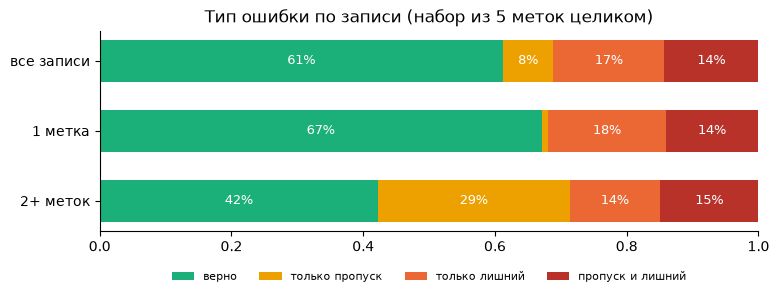

In [2]:
ops = threshold_metrics(b.y, b.p_cal, b.thresholds, C)
rank = multilabel_metrics(b.y, b.p_cal, C)
tab = pd.DataFrame({
    c: {"n_pos": int(b.y[:, i].sum()), "порог": b.thresholds[i], **{k: ops["per_class"][c][k] for k in ("tp", "fp", "fn")},
        "precision": ops["per_class"][c]["precision"], "recall": ops["per_class"][c]["recall"],
        "F1": ops["per_class"][c]["f1"], "AUROC": rank["auroc"][c]}
    for i, c in enumerate(C)}).T
display(tab.round(3))
print(f"macro F1 (in-sample пороги): {ops['macro_f1']:.3f} | micro F1: {ops['micro_f1']:.3f}")

# --- уровень записи: полностью верный набор меток / какие бывают ошибки
types = ea.record_error_types(b.y, b.pred)
order = ["верно", "только пропуск", "только лишний", "пропуск и лишний"]
n_lab = b.y.sum(axis=1)
groups = {"все записи": np.ones(len(b.y), bool), "1 метка": n_lab == 1, "2+ меток": n_lab >= 2}
share = pd.DataFrame({g: types[m].value_counts(normalize=True).reindex(order).fillna(0) for g, m in groups.items()}).T
cnt = pd.DataFrame({g: types[m].value_counts().reindex(order).fillna(0).astype(int) for g, m in groups.items()}).T
display(pd.concat({"доля": share.round(3), "число": cnt}, axis=1))

colors = ["#1baf7a", "#eda100", "#eb6834", "#b8322a"]
fig, ax = plt.subplots(figsize=(8.5, 2.6))
left = np.zeros(len(share))
for k, (name, col) in enumerate(zip(order, colors)):
    ax.barh(share.index[::-1], share[name].to_numpy()[::-1], left=left, color=col, label=name, height=0.6)
    for yy, (l, w) in enumerate(zip(left, share[name].to_numpy()[::-1])):
        if w > 0.04:
            ax.text(l + w / 2, yy, f"{w:.0%}", ha="center", va="center", fontsize=9, color="white")
    left += share[name].to_numpy()[::-1]
ax.set(xlim=(0, 1), title="Тип ошибки по записи (набор из 5 меток целиком)")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False, fontsize=8)
ax.grid(False); plt.show()

**Вывод.** Набор из 5 меток целиком угадан у 61.2% записей (1313 из 2146). У записей с одной истинной меткой — 67.1%, с двумя и более — 42.2%.
Ошибки неодинаковы по типу: у одно-метковых записей почти нет «только пропусков» (1.0%), зато 17.8% — лишний предсказанный класс и ещё 14.1% — лишний класс вместе с пропуском;
у много-метковых записей главная ошибка — пропуск метки (29.1% «только пропуск»). Ложных срабатываний при порогах по F1 больше, чем пропусков (751 против 507 по сумме классов).
По классам (пороги подобраны на этом же val, значения слегка оптимистичны): F1 лучше всего у NORM (0.863), хуже всего у HYP (0.619; precision 0.62, recall 0.62).
У NORM, MI и STTC precision (0.81 / 0.71 / 0.69) ниже recall (0.93 / 0.80 / 0.82), у CD наоборот (0.85 против 0.72): порог CD «осторожнее».
AUROC по классам при этом близок (0.90–0.94) — то есть различия в F1 отчасти определяются тем, где поставлен порог, а не только ранжированием.

## 2. Какие классы путаются

Задача multi-label, поэтому классической матрицы ошибок 5×5 нет. Три представления:
1. записи ровно с **одной** истинной меткой: какие классы модель на них предсказывает;
2. для каждого класса — **откуда берутся ложные срабатывания** (какие истинные наборы меток у этих записей) и **куда уходят пропуски** (что модель предсказала вместо класса);
3. полнота для записей с одной и с несколькими истинными метками.

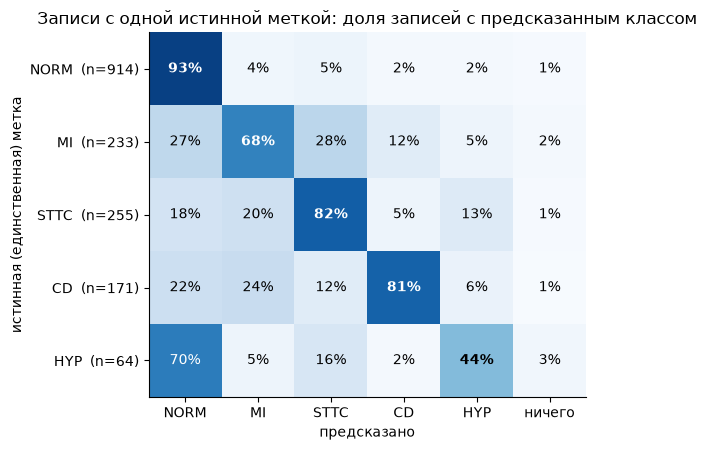

Строка в сумме может превышать 100%: модель может предсказать несколько классов сразу.


In [3]:
mat, n_row = ea.single_label_confusion(b.y, b.pred, C)
fig, ax = plt.subplots(figsize=(6.6, 4.6))
im = ax.imshow(mat.to_numpy(), cmap="Blues", vmin=0, vmax=1)
ax.grid(False)
for r in range(mat.shape[0]):
    for k in range(mat.shape[1]):
        v = mat.iat[r, k]
        ax.text(k, r, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.5 else "black", fontsize=10,
                fontweight="bold" if r == k else "normal")
ax.set_xticks(range(mat.shape[1]), list(mat.columns))
ax.set_yticks(range(mat.shape[0]), [f"{c}  (n={n_row[c]})" for c in mat.index])
ax.set(xlabel="предсказано", ylabel="истинная (единственная) метка",
       title="Записи с одной истинной меткой: доля записей с предсказанным классом")
plt.tight_layout(); plt.show()
print("Строка в сумме может превышать 100%: модель может предсказать несколько классов сразу.")

**Вывод.** На записях с одной меткой классы нормы и «чистых» поражений различаются неодинаково хорошо: верно предсказано NORM 93%, STTC 82%, CD 81%, MI 68%, HYP 44% (у HYP всего 64 таких записи).
Главная путаница — уход абнормальных записей в **NORM**: 27% MI-записей, 22% CD, 18% STTC и 70% HYP-записей получают предсказание NORM. Обратное редко: у NORM-записей любой другой класс предсказан не чаще 5%.
Вторая заметная пара — **MI ↔ STTC**: 28% «чистых» MI предсказаны как STTC, 20% «чистых» STTC — как MI; а также CD → MI (24%).
У STTC-записей 13% получают лишний HYP (у NORM — 2%). Почему именно эти пары — из этих данных неочевидно: я проверяю только то, где ошибки, а не их физиологическую причину
(в `01_eda` отмечено, что MI+STTC и STTC+HYP — частые сочетания меток; возможно, это связано, но здесь это не проверялось).

In [4]:
frames = {}
for j, c in enumerate(C):
    fp = ea.error_sources(b.y, b.pred, C, j, "fp", 4).rename(columns={"n": "n", "доля": "доля"})
    fn = ea.error_sources(b.y, b.pred, C, j, "fn", 4)
    n_fp = int(((b.pred[:, j] == 1) & (b.y[:, j] == 0)).sum()); n_fn = int(((b.pred[:, j] == 0) & (b.y[:, j] == 1)).sum())
    frames[(c, f"ложных срабатываний {n_fp}: истинный набор меток")] = fp
    frames[(c, f"пропусков {n_fn}: предсказано вместо класса")] = fn
for (c, title), df in frames.items():
    print(f"\n[{c}] {title}")
    print(df.assign(доля=df["доля"].map("{:.0%}".format)).to_string())


[NORM] ложных срабатываний 214: истинный набор меток
       n доля
MI    63  29%
STTC  46  21%
HYP   45  21%
CD    37  17%

[NORM] пропусков 67: предсказано вместо класса
           n доля
STTC      22  33%
MI        16  24%
ничего     8  12%
STTC+HYP   6   9%

[MI] ложных срабатываний 180: истинный набор меток
          n доля
STTC     52  29%
CD       41  23%
NORM     35  19%
STTC+CD  17   9%

[MI] пропусков 107: предсказано вместо класса
           n доля
NORM      46  43%
STTC      21  20%
STTC+HYP   9   8%
CD         9   8%

[STTC] ложных срабатываний 193: истинный набор меток
        n доля
MI     66  34%
NORM   47  24%
MI+CD  34  18%
CD     20  10%

[STTC] пропусков 93: предсказано вместо класса
         n доля
NORM    35  38%
MI      28  30%
MI+CD   10  11%
CD+HYP   4   4%

[CD] ложных срабатываний 64: истинный набор меток
          n доля
MI       27  42%
NORM     17  27%
STTC     12  19%
MI+STTC   3   5%

[CD] пропусков 137: предсказано вместо класса
           n доля
NORM  

**Вывод.** Пропуски у всех четырёх абнормальных классов в основном заканчиваются предсказанием **NORM**: MI 43% пропусков, CD 38%, HYP 38%, STTC 38% (по таблицам выше).
Пропущенный NORM чаще всего превращается в STTC (33%) или MI (24%), у 12% не предсказано ничего.
Ложные срабатывания берутся в основном из соседних патологий: MI — из записей STTC (29%), CD (23%) и NORM (19%); STTC — из MI (34%), NORM (24%) и MI+CD (18%);
CD — из MI (42%) и NORM (27%); HYP — из STTC (32%) и NORM (17%); NORM — из MI (29%), STTC (21%), HYP (21%) и CD (17%). Обратите внимание: у каждой записи есть хотя бы одна истинная метка (записи без суперкласса исключены),
поэтому «ложное срабатывание» всегда означает запись с *другой* патологией или нормой. Объяснять каждую пару физиологией я не берусь: по данным видно только, куда уходят предсказания.

In [5]:
rows = []
for j, c in enumerate(C):
    pos = b.y[:, j] == 1
    for name, m in (("1 метка", n_lab == 1), ("2+ меток", n_lab >= 2)):
        sel = pos & m
        k, n = int((b.pred[sel, j] == 1).sum()), int(sel.sum())
        ci = binomtest(k, n).proportion_ci(method="wilson") if n else None
        rows.append({"класс": c, "записи с классом": name, "n": n, "recall": k / n if n else np.nan,
                     "95% (Уилсон)": f"{ci.low:.2f}–{ci.high:.2f}" if ci else ""})
rec_tab = pd.DataFrame(rows).pivot(index="класс", columns="записи с классом", values=["n", "recall", "95% (Уилсон)"]).loc[C]
display(rec_tab)

n             recall           95% (Уилсон)           
записи с классом 1 метка 2+ меток   1 метка  2+ меток      1 метка   2+ меток
класс                                                                        
NORM                 914       41  0.934354  0.829268    0.92–0.95  0.69–0.91
MI                   233      307  0.682403  0.892508    0.62–0.74  0.85–0.92
STTC                 255      273  0.823529  0.824176    0.77–0.87  0.77–0.86
CD                   171      324  0.807018  0.679012    0.74–0.86  0.63–0.73
HYP                   64      204    0.4375  0.671569    0.32–0.56  0.60–0.73

**Вывод.** Полнота зависит от того, один ли у записи диагноз. MI: 0.68 на записях с одной меткой против 0.89 на записях с несколькими (интервалы Уилсона 0.62–0.74 и 0.85–0.92 не пересекаются);
HYP: 0.44 против 0.67 (0.32–0.56 и 0.60–0.73); CD — наоборот, 0.81 против 0.68 (0.74–0.86 и 0.63–0.73); STTC одинаково (0.82 и 0.82); NORM с другими метками — всего 41 запись, интервал широкий.
Интервалы Уилсона не учитывают повторные записи одного пациента, поэтому чуть узки. Возможная причина (MI и HYP «поднимаются» вместе с сопутствующей патологией) — только гипотеза, она не проверялась.

In [6]:
# Полнота по отдельным кодам SCP внутри класса: из каких кодов собран суперкласс и какие из них модель находит хуже
sup = ea.label_support(b.meta["scp_codes"], b.scp, C)   # (N, C): макс. likelihood кодов класса у записи
code_to_class = b.scp["diagnostic_class"].dropna().to_dict()
rows = []
for r, d in enumerate(b.meta["scp_codes"]):
    for code_, lik in d.items():
        cls = code_to_class.get(code_)
        if cls in C:
            rows.append({"класс": cls, "код": code_, "lik": lik, "pred": int(b.pred[r, C.index(cls)])})
cd = pd.DataFrame(rows)
g = cd.groupby(["класс", "код"]).agg(n=("pred", "size"), recall=("pred", "mean"))
g100 = cd[cd["lik"] == 100].groupby(["класс", "код"]).agg(n_lik100=("pred", "size"), recall_lik100=("pred", "mean"))
tab_code = g.join(g100).reset_index()
tab_code["описание"] = tab_code["код"].map(b.scp["description"]) if "description" in b.scp else ""
tab_code = tab_code[tab_code["n"] >= 15]
tab_code["класс"] = pd.Categorical(tab_code["класс"], C, ordered=True)
display(tab_code.sort_values(["класс", "n"], ascending=[True, False]).round(2).reset_index(drop=True))
print("n — записей с этим кодом (в любой likelihood), n_lik100 — с этим кодом при likelihood=100; коды с n<15 не показаны.")

,класс,код,n,recall,n_lik100,recall_lik100,описание
0,NORM,NORM,955,0.93,708.0,0.94,normal ECG
1,MI,IMI,266,0.77,87.0,0.93,inferior myocardial infarction
2,MI,ASMI,236,0.90,156.0,0.96,anteroseptal myocardial infarction
3,MI,ILMI,47,0.87,31.0,0.97,inferolateral myocardial infarction
4,MI,AMI,36,0.81,15.0,0.87,anterior myocardial infarction
5,MI,ALMI,29,0.93,22.0,0.95,anterolateral myocardial infarction
6,MI,INJAS,21,0.90,19.0,0.95,subendocardial injury in anteroseptal leads
7,MI,LMI,20,0.45,5.0,0.40,lateral myocardial infarction
8,MI,INJAL,15,0.93,12.0,1.00,subendocardial injury in anterolateral leads
9,STTC,NDT,182,0.76,181.0,0.76,non-diagnostic T abnormalities


n — записей с этим кодом (в любой likelihood), n_lik100 — с этим кодом при likelihood=100; коды с n<15 не показаны.


**Вывод.** Внутри суперкласса полнота очень неоднородна — слабые места видны на уровне кодов SCP.
**HYP:** LVH находится на 0.72 (но на 0.92, если взять только записи с likelihood = 100; n=97), а LAO/LAE — на 0.28 (n=43, и при likelihood 100 тоже 0.26). Суперкласс HYP по `scp_statements.csv` включает и этот код, и это один из тех, что тянут полноту HYP вниз.
**CD:** CRBBB 0.98 и CLBBB 0.96 найдены почти всегда, LAFB 0.89, IRBBB 0.73, 1AVB 0.57, **IVCD 0.42** (n=78, все при likelihood 100) — слабая метка здесь не причина.
**MI:** IMI 0.77 в целом, но 0.93 при likelihood = 100 (n=87), то есть провал — в записях со слабой меткой; LMI 0.45 (n=20, мало записей).
**STTC:** NDT 0.76 (n=182, все с likelihood 100) — самый слабый из крупных кодов; ISC_ 0.94, NST_ 0.83.
Почему модель плохо находит LAO/LAE, IVCD, NDT — из этих данных **неочевидно**; это вопрос к специалисту, а не вывод анализа. Коды с n < 15 не показаны, интервалов нет — цифры на малых n ориентировочные.

## 3. Зависимость качества от возраста и пола

Метрики по срезам: AUROC (не зависит от порога), полнота и доля ложных срабатываний (FPR) при порогах модели.
Интервалы — бутстреп по пациентам (95%, 1000 реплик). Если в срезе меньше 20 положительных (или отрицательных) записей класса,
метрика не показывается. Модель на вход получает только сигнал: возраст и пол ей неизвестны.
Из-за числа сравнений (6 панелей × 3 метрики × срезы) отдельные «значимые» различия можно ждать и случайно.

In [7]:
age = b.meta["age"]
print("Уникальные значения age больше 89:", sorted(age[age > 89].unique()), "| таких записей:", int((age > 89).sum()))
print("Минимальный возраст:", age.min(), "| пропусков age:", int(age.isna().sum()), "| пропусков sex:", int(b.meta['sex'].isna().sum()))
hw = b.meta.groupby("sex")[["height", "weight"]].mean().round(1)
display(hw)
assert hw.loc[0, "height"] > hw.loc[1, "height"] and hw.loc[0, "weight"] > hw.loc[1, "weight"]
print("Средние рост и вес у sex=0 больше -> считаю sex=0 мужчины (М), sex=1 женщины (Ж); это вывод из данных, не из документации.")

age_grp = pd.Series(pd.cut(age.to_numpy(), cfg["age"]["bins"], right=False, labels=cfg["age"]["labels"]), index=age.index)
sex_name = np.where(b.meta["sex"] == 0, "М", "Ж")
comp = pd.crosstab(age_grp, sex_name)
comp["всего"] = comp.sum(axis=1)
prev = pd.DataFrame({c: pd.Series(b.y[:, j]).groupby(age_grp.to_numpy()).mean() for j, c in enumerate(C)}).loc[cfg["age"]["labels"]]
display(pd.concat({"записей": comp, "доля класса в группе": (prev * 100).round(0).astype(int).astype(str) + "%"}, axis=1))

Уникальные значения age больше 89: [np.float64(300.0)] | таких записей: 41
Минимальный возраст: 3.0 | пропусков age: 0 | пропусков sex: 0


,height,weight
sex,,
0,173.2,78.1
1,161.1,65.1


Средние рост и вес у sex=0 больше -> считаю sex=0 мужчины (М), sex=1 женщины (Ж); это вывод из данных, не из документации.


записей            доля класса в группе                    
            Ж    М всего                 NORM   MI STTC   CD  HYP
<40       165  118   283                  82%   3%   6%  11%   6%
40–49     101  153   254                  70%  13%  11%  12%   6%
50–59     143  266   409                  59%  15%  20%  13%   9%
60–69     209  268   477                  35%  31%  28%  21%  15%
70–79     229  212   441                  26%  36%  33%  34%  15%
80–89     151   90   241                   9%  45%  44%  41%  23%
90+        34    7    41                   2%  46%  34%  66%  22%

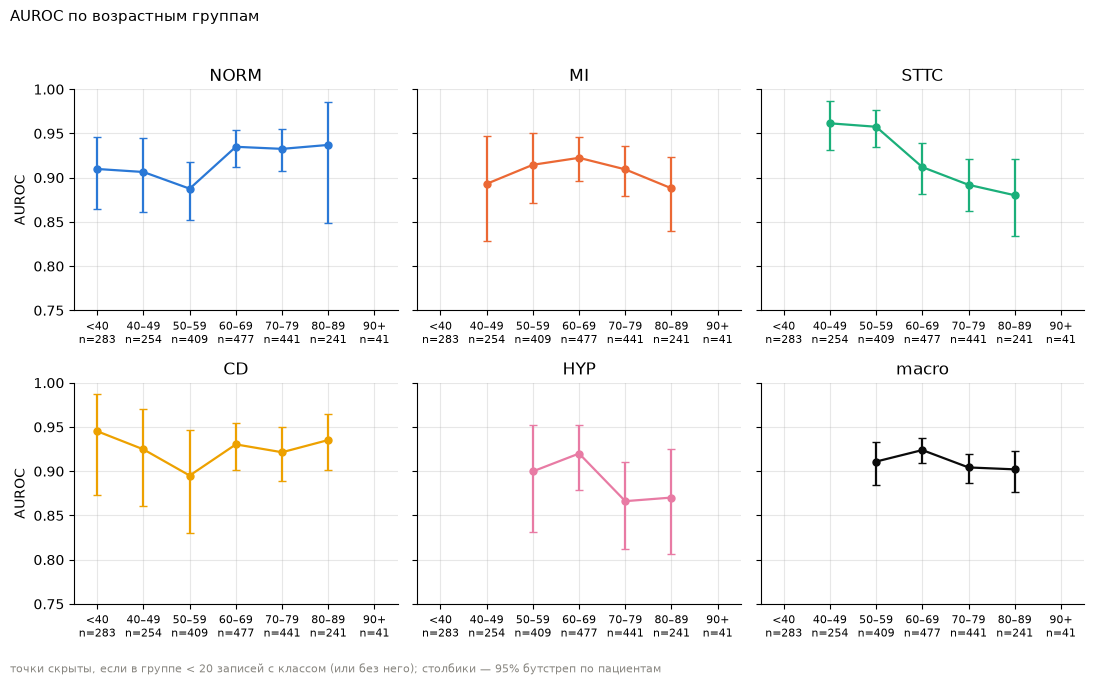

класс,NORM,MI,STTC,CD,HYP,macro
группа,,,,,,
<40,0.910 [0.865; 0.946],—,—,0.945 [0.873; 0.987],—,—
40–49,0.906 [0.861; 0.944],0.893 [0.829; 0.947],0.961 [0.931; 0.987],0.925 [0.861; 0.970],—,—
50–59,0.888 [0.853; 0.917],0.915 [0.871; 0.951],0.958 [0.935; 0.976],0.895 [0.830; 0.946],0.900 [0.831; 0.953],0.911 [0.885; 0.934]
60–69,0.935 [0.912; 0.954],0.922 [0.897; 0.946],0.912 [0.881; 0.939],0.930 [0.901; 0.954],0.920 [0.879; 0.953],0.924 [0.910; 0.937]
70–79,0.933 [0.907; 0.955],0.909 [0.879; 0.936],0.892 [0.862; 0.921],0.921 [0.889; 0.950],0.866 [0.812; 0.911],0.904 [0.887; 0.920]
80–89,0.937 [0.849; 0.986],0.888 [0.840; 0.924],0.880 [0.835; 0.922],0.935 [0.902; 0.965],0.870 [0.807; 0.925],0.902 [0.876; 0.923]
90+,—,—,—,—,—,—


In [8]:
age_lab = cfg["age"]["labels"]
masks_age = [(age_grp == g).to_numpy() for g in age_lab]
pt_a, bt_a = ea.subgroup_bootstrap(b.y, b.p_cal, b.pred, masks_age, b.patient_id, BOOT["n_boot"], SEED)
fr_age = ea.subgroup_frame(pt_a, bt_a, age_lab, masks_age, b.y, C, BOOT["ci_level"], BOOT["min_valid_share"], cfg["min_pos"])
note = f"точки скрыты, если в группе < {cfg['min_pos']} записей с классом (или без него); столбики — 95% бутстреп по пациентам"
fig = ea.plot_metric_by_group(fr_age, "auroc", age_lab, C, "AUROC по возрастным группам", "AUROC", CLASS_COLORS, (0.75, 1.0), note=note)
plt.show()
wide = fr_age[fr_age["метрика"] == "auroc"].assign(
    v=lambda d: d.apply(lambda r: "—" if np.isnan(r["значение"]) else f"{r['значение']:.3f} [{r['lo']:.3f}; {r['hi']:.3f}]", axis=1)
).pivot(index="группа", columns="класс", values="v").loc[age_lab, C + ["macro"]]
display(wide)

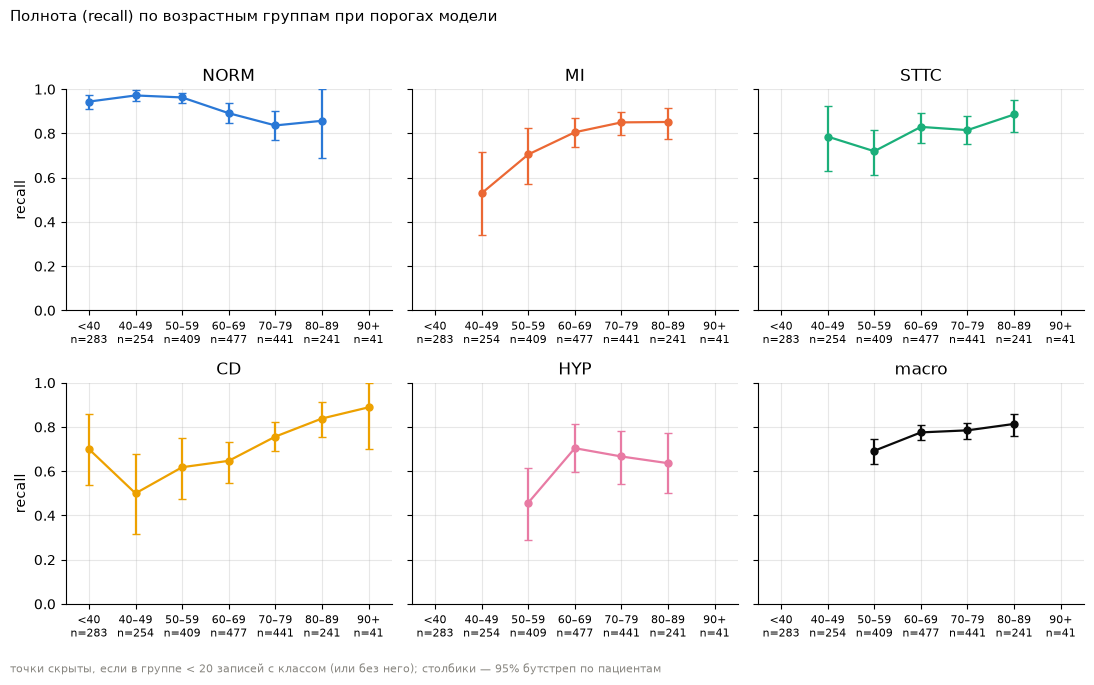

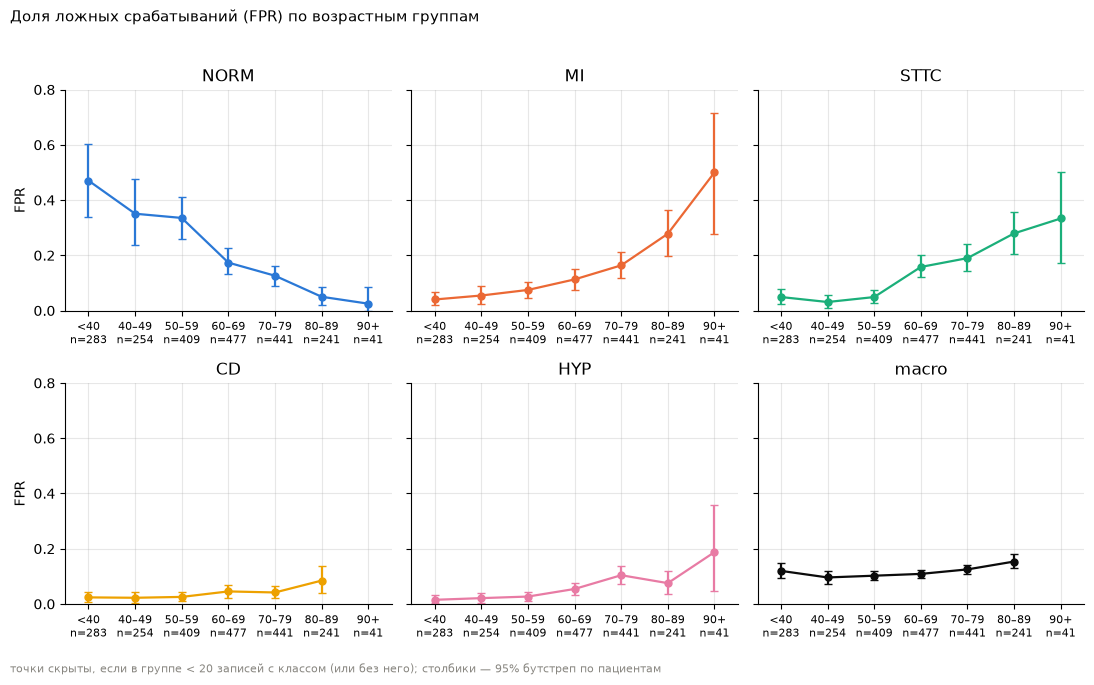

In [9]:
fig = ea.plot_metric_by_group(fr_age, "recall", age_lab, C, "Полнота (recall) по возрастным группам при порогах модели", "recall",
                              CLASS_COLORS, (0.0, 1.0), note=note)
plt.show()
fig = ea.plot_metric_by_group(fr_age, "fpr", age_lab, C, "Доля ложных срабатываний (FPR) по возрастным группам", "FPR",
                              CLASS_COLORS, (0.0, 0.8), note=note)
plt.show()

**Вывод.** Возрастные группы различаются прежде всего *составом задачи*: доля NORM падает с 82% (<40) до 9% (80–89), доля MI растёт с 3% до 45%, у 90+ всего 41 запись — метрики там не показаны.
Для молодых групп (<40, 40–49) AUROC скрыт у большинства классов из-за малого числа положительных (<20), поэтому macro AUROC можно сравнивать только для 50–89 лет: 0.911 (50–59), 0.924 (60–69), 0.904 (70–79), 0.902 (80–89)
— интервалы широко перекрываются, явной общей тенденции нет.
По классам тенденции разные: **AUROC STTC убывает с возрастом** (0.961 в 40–49 → 0.880 в 80–89), **AUROC NORM, наоборот, выше у старших** (0.89 в 50–59 → 0.93–0.94 в 60+), HYP ниже в 70+ (0.866–0.870 против 0.920 в 60–69) с широкими интервалами.
Рабочая точка при фиксированных порогах от возраста зависит гораздо сильнее, чем AUROC (графики полноты и FPR выше): подробно — в следующем блоке.

In [10]:
# Прямое сравнение «моложе 60» и «70 и старше» (разность метрик с бутстреп-интервалом)
masks_ya = [(age < 60).to_numpy(), (age >= 70).to_numpy()]
pt_y, bt_y = ea.subgroup_bootstrap(b.y, b.p_cal, b.pred, masks_ya, b.patient_id, BOOT["n_boot"], SEED)
d, lo, hi = ea.difference_ci(pt_y, bt_y, 0, 1, BOOT["ci_level"])
rows = []
for k, metric in enumerate(ea.METRICS):
    for j, c in enumerate(C + ["macro"]):
        rows.append({"метрика": metric, "класс": c, "моложе 60": pt_y[0, k, j], "70+": pt_y[1, k, j],
                     "разность (моложе − 70+)": d[k, j], "lo": lo[k, j], "hi": hi[k, j],
                     "CI без нуля": bool(lo[k, j] > 0 or hi[k, j] < 0)})
cmp_age = pd.DataFrame(rows)
print(f"моложе 60: n={masks_ya[0].sum()}, 70+: n={masks_ya[1].sum()}")
display(cmp_age.pivot(index="класс", columns="метрика", values="разность (моложе − 70+)").loc[C + ["macro"]].round(3))
print("Разности, у которых 95% интервал не содержит 0:")
display(cmp_age[cmp_age["CI без нуля"]].round(3).reset_index(drop=True))

моложе 60: n=946, 70+: n=723


метрика,auroc,fpr,recall
класс,,,
NORM,-0.044,0.272,0.118
MI,0.017,-0.157,-0.226
STTC,0.077,-0.181,-0.083
CD,-0.012,-0.037,-0.190
HYP,0.044,-0.078,-0.206
macro,0.016,-0.036,-0.117


Разности, у которых 95% интервал не содержит 0:


,метрика,класс,моложе 60,70+,разность (моложе − 70+),lo,hi,CI без нуля
0,auroc,NORM,0.898,0.943,-0.044,-0.073,-0.013,True
1,auroc,STTC,0.965,0.888,0.077,0.051,0.106,True
2,recall,NORM,0.959,0.841,0.118,0.059,0.182,True
3,recall,MI,0.635,0.861,-0.226,-0.344,-0.120,True
4,recall,CD,0.609,0.799,-0.190,-0.286,-0.088,True
5,recall,HYP,0.448,0.654,-0.206,-0.352,-0.052,True
6,recall,macro,0.683,0.801,-0.117,-0.169,-0.067,True
7,fpr,NORM,0.363,0.091,0.272,0.205,0.336,True
8,fpr,MI,0.058,0.216,-0.157,-0.202,-0.114,True
9,fpr,STTC,0.044,0.225,-0.181,-0.226,-0.139,True


**Вывод.** Сравнение «моложе 60» (n=946) и «70+» (n=723). **AUROC:** значимо различаются только NORM (моложе хуже: −0.044, интервал −0.073…−0.013) и STTC (моложе лучше: +0.077, 0.051…0.106);
у MI, CD, HYP и macro интервалы содержат 0 (macro: +0.016).
**При фиксированных порогах картина резче:** у моложе 60 модель заметно чаще говорит «норма» и реже — патология. Полнота (моложе / 70+): macro 0.68 / 0.80, MI 0.64 / 0.86, CD 0.61 / 0.80, HYP 0.45 / 0.65, но NORM 0.96 / 0.84.
FPR (моложе / 70+): NORM 0.36 / 0.09, MI 0.06 / 0.22, STTC 0.04 / 0.23. Все эти разности значимы по 95% интервалу.
То есть пороги, подобранные на всём val, для молодых «слишком мягки к норме», для старших — «слишком строги». Это согласуется с тем, что доли классов сильно зависят от возраста; модель возраст не получает, а как она к нему «приходит» через сигнал — не исследовалось.

In [11]:
# Проверка гипотез о причине возрастных различий (только то, что можно проверить по данным).
# (а) Не дело ли в «слабых» метках (likelihood < 100)? Доля слабых меток и полнота только по меткам с likelihood = 100.
young, old = (age < 60).to_numpy(), (age >= 70).to_numpy()
rows = []
for j, c in enumerate(C):
    pos = b.y[:, j] == 1
    for name, m in (("<60", young), ("70+", old)):
        s = pos & m
        strong = s & (sup[:, j] == 100)
        rows.append({"класс": c, "возраст": name, "n положит.": int(s.sum()), "доля меток lik<100": (s & (sup[:, j] < 100)).sum() / max(s.sum(), 1),
                     "recall (все)": b.pred[s, j].mean(), "n lik=100": int(strong.sum()),
                     "recall (lik=100)": b.pred[strong, j].mean() if strong.any() else np.nan})
display(pd.DataFrame(rows).round(2).pivot(index="класс", columns="возраст").loc[C].swaplevel(axis=1).sort_index(axis=1, level=0))

# (б) NORM: доля записей БЕЗ метки NORM, которым модель всё же ставит NORM, по возрасту и силе метки записи
jn = C.index("NORM")
non_norm = b.y[:, jn] == 0
has_strong = np.nanmax(np.where(b.y == 1, sup, np.nan), axis=1) == 100   # у записи есть метка с likelihood = 100
rows = []
for name, m in (("<60", young), ("70+", old)):
    for sname, sm in (("есть метка lik=100", has_strong), ("все метки lik<100", ~has_strong)):
        s = non_norm & m & sm
        rows.append({"возраст": name, "записи без NORM": sname, "n": int(s.sum()), "модель предсказала NORM": b.pred[s, jn].mean()})
display(pd.DataFrame(rows).round(2))

возраст       70+                                                                   <60                                                            
        n lik=100 n положит. recall (lik=100) recall (все) доля меток lik<100 n lik=100 n положит. recall (lik=100) recall (все) доля меток lik<100
класс                                                                                                                                              
NORM           82        138             0.83         0.84               0.41       506        651             0.97         0.96               0.22
MI            154        287             0.94         0.86               0.46        43        104             0.91         0.63               0.59
STTC          219        265             0.87         0.85               0.17       114        128             0.77         0.77               0.11
CD            273        278             0.80         0.80               0.02       111        115             0.62         0.61               0.03
HYP            72        130             0.74         0.65               0.45        26         67             0.58         0.45               0.61

,возраст,записи без NORM,n,модель предсказала NORM
0,<60,есть метка lik=100,220,0.26
1,<60,все метки lik<100,75,0.65
2,70+,есть метка lik=100,507,0.06
3,70+,все метки lik<100,78,0.31


In [12]:
# (в) STTC: AUROC падает с возрастом. Меняется ли состав отрицательных (против кого ранжируем STTC)?
js = C.index("STTC")
pos_s = b.y[:, js] == 1
neg_norm = (b.y[:, jn] == 1) & ~pos_s
neg_abn = (b.y[:, jn] == 0) & ~pos_s
combos = {(a, nm): (am, nmask) for a, am in (("<60", young), ("70+", old)) for nm, nmask in (("NORM", neg_norm), ("другие аномальные", neg_abn))}

def stat(idx):
    out = []
    for am, nmask in combos.values():
        sel = idx[am[idx] & (pos_s[idx] | nmask[idx])]
        out.append(ea.safe_auroc(pos_s[sel].astype(int), b.p_cal[sel, js]))
    return np.array(out)

point = stat(np.arange(len(b.y)))
boot = ea.cluster_bootstrap(stat, b.patient_id, BOOT["n_boot"], SEED)
lo, hi = ea.percentile_ci(boot, BOOT["ci_level"], BOOT["min_valid_share"])
rows = []
for k, ((a, nm), (am, nmask)) in enumerate(combos.items()):
    rows.append({"возраст": a, "STTC против": nm, "n STTC": int((am & pos_s).sum()), "n отриц.": int((am & nmask).sum()),
                 "AUROC": point[k], "95% интервал": f"{lo[k]:.3f}–{hi[k]:.3f}"})
display(pd.DataFrame(rows).round(3))

,возраст,STTC против,n STTC,n отриц.,AUROC,95% интервал
0,<60,NORM,128,651,0.974,0.963–0.984
1,<60,другие аномальные,128,167,0.932,0.905–0.957
2,70+,NORM,265,134,0.949,0.924–0.970
3,70+,другие аномальные,265,324,0.863,0.831–0.892


**Вывод.** Проверка трёх гипотез, объясняющих возрастные различия (только то, что можно проверить по данным):
**(а) Слабые метки.** Для MI различие полноты в основном исчезает: среди записей с меткой likelihood = 100 полнота 0.91 (<60, n=43) против 0.94 (70+, n=154), хотя по всем записям 0.63 против 0.86 —
у молодых 59% MI-меток слабые (likelihood < 100) против 46% у старших. Для HYP слабых меток 61% против 45%; полнота по сильным 0.58 против 0.74 (n=26 и 72) — разрыв уменьшился, но не исчез.
Для CD слабых меток почти нет (3% и 2%), а полнота всё равно 0.61 против 0.80 — **здесь метки не объясняют различие, причина неочевидна**.
**(б) NORM.** Среди записей без метки NORM модель всё равно ставит NORM у 26% записей моложе 60 с сильной меткой (n=220) против 6% у 70+ (n=507); если все метки слабые — 65% против 31% (n=75 и 78).
Слабость метки повышает долю в обеих группах, но возрастной разрыв остаётся в каждой страте — снова не объясняется только метками.
**(в) STTC.** AUROC STTC против записей NORM: 0.974 (<60) и 0.949 (70+); против *других патологий*: 0.932 и 0.863 (интервалы 0.905–0.957 и 0.831–0.892 не пересекаются).
У старших среди отрицательных 71% патологии (324 из 458), у молодых — 20% (167 из 818): часть падения AUROC STTC с возрастом объясняется «более трудными» отрицательными, но и внутри патологических отрицательных у старших AUROC ниже — полностью состав не объясняет.
Остаётся неясным, почему NORM ранжируется лучше у старших, а STTC хуже: гипотезы выше проверены частично, ни одна не закрывает эффект целиком.

М: n=1114, Ж: n=1032


М      Ж  М − Ж     lo     hi  CI без нуля
метрика класс                                                
auroc   NORM   0.936  0.945 -0.010 -0.029  0.010        False
        MI     0.932  0.920  0.012 -0.012  0.037        False
        STTC   0.921  0.941 -0.020 -0.044  0.001        False
        CD     0.930  0.940 -0.009 -0.034  0.019        False
        HYP    0.898  0.910 -0.013 -0.055  0.029        False
        macro  0.923  0.931 -0.008 -0.022  0.006        False
recall  NORM   0.932  0.928  0.004 -0.027  0.037        False
        MI     0.823  0.774  0.049 -0.024  0.121        False
        STTC   0.803  0.842 -0.038 -0.103  0.027        False
        CD     0.717  0.730 -0.013 -0.092  0.071        False
        HYP    0.635  0.587  0.048 -0.076  0.183        False
        macro  0.782  0.772  0.010 -0.027  0.050        False
fpr     NORM   0.184  0.174  0.010 -0.037  0.057        False
        MI     0.119  0.105  0.015 -0.017  0.046        False
        STTC   0.116  0.123 -0.007 -0.041  0.025        False
        CD     0.042  0.035  0.007 -0.012  0.027        False
        HYP    0.066  0.040  0.026  0.005  0.046         True
        macro  0.106  0.095  0.010 -0.002  0.022        False

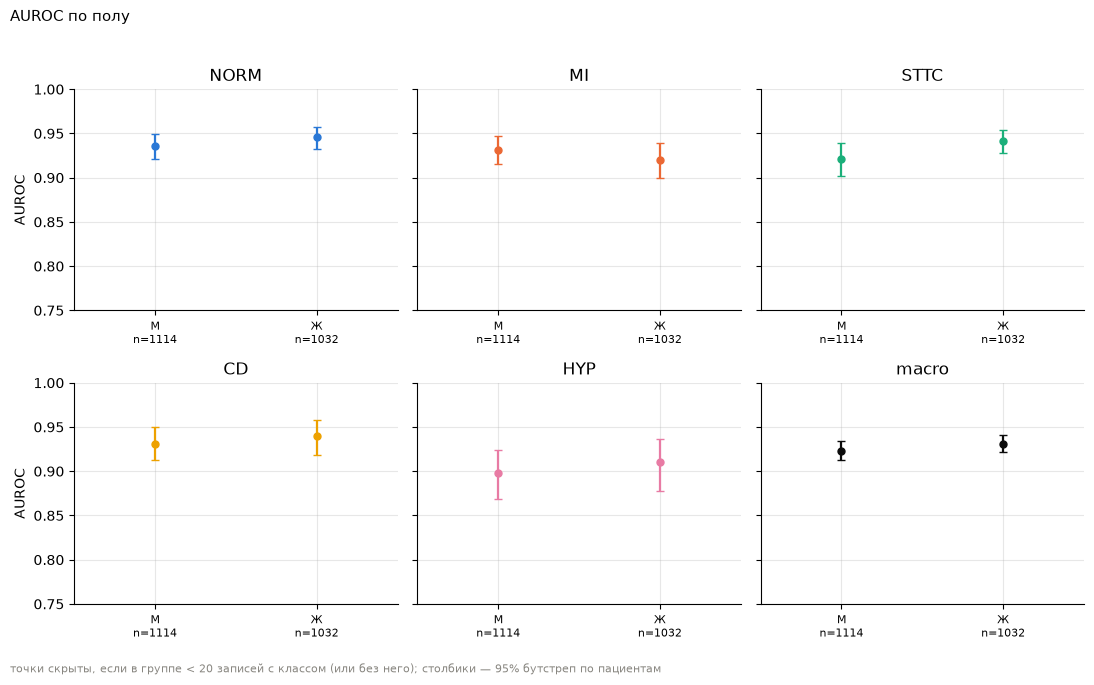

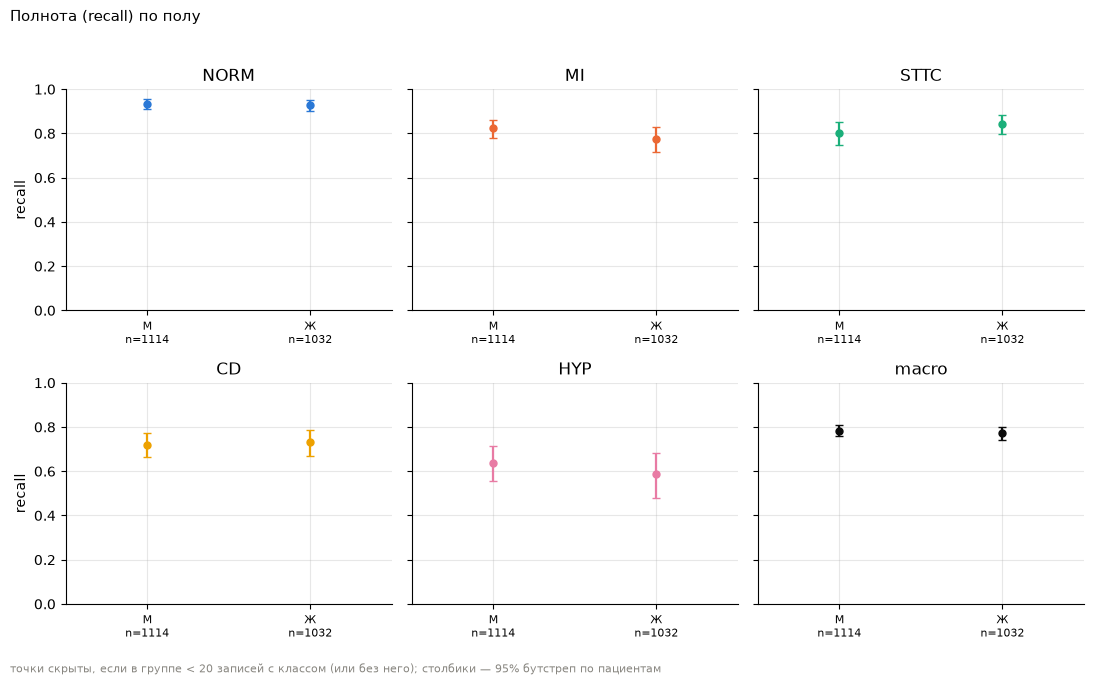

Различий с интервалом без нуля: 1 из 18 проверенных (ожидаемо случайных при 95%: ≈0.9)


In [13]:
masks_sex = [(b.meta["sex"] == 0).to_numpy(), (b.meta["sex"] == 1).to_numpy()]
sex_lab = ["М", "Ж"]
pt_s, bt_s = ea.subgroup_bootstrap(b.y, b.p_cal, b.pred, masks_sex, b.patient_id, BOOT["n_boot"], SEED)
fr_sex = ea.subgroup_frame(pt_s, bt_s, sex_lab, masks_sex, b.y, C, BOOT["ci_level"], BOOT["min_valid_share"], cfg["min_pos"])
d, lo, hi = ea.difference_ci(pt_s, bt_s, 0, 1, BOOT["ci_level"])
rows = []
for k, metric in enumerate(ea.METRICS):
    for j, c in enumerate(C + ["macro"]):
        rows.append({"метрика": metric, "класс": c, "М": pt_s[0, k, j], "Ж": pt_s[1, k, j], "М − Ж": d[k, j],
                     "lo": lo[k, j], "hi": hi[k, j], "CI без нуля": bool(lo[k, j] > 0 or hi[k, j] < 0)})
cmp_sex = pd.DataFrame(rows)
print(f"М: n={masks_sex[0].sum()}, Ж: n={masks_sex[1].sum()}")
display(cmp_sex.round(3).set_index(["метрика", "класс"]))
fig = ea.plot_metric_by_group(fr_sex, "auroc", sex_lab, C, "AUROC по полу", "AUROC", CLASS_COLORS, (0.75, 1.0), connect=False, note=note)
plt.show()
fig = ea.plot_metric_by_group(fr_sex, "recall", sex_lab, C, "Полнота (recall) по полу", "recall", CLASS_COLORS, (0.0, 1.0), connect=False, note=note)
plt.show()
n_tests = len(cmp_sex)
print(f"Различий с интервалом без нуля: {int(cmp_sex['CI без нуля'].sum())} из {n_tests} проверенных (ожидаемо случайных при 95%: ≈{0.05 * n_tests:.1f})")

In [14]:
# Возраст и пол могут быть связаны (в группах 80+ женщин больше) -> сравнение полов внутри двух возрастных страт
strata = {"<60": age < 60, "60+": age >= 60}
masks_st, names_st = [], []
for sname, sm in strata.items():
    for k, s in enumerate((0, 1)):
        masks_st.append((sm & (b.meta["sex"] == s)).to_numpy()); names_st.append(f"{sname} {sex_lab[k]}")
pt_t, bt_t = ea.subgroup_bootstrap(b.y, b.p_cal, b.pred, masks_st, b.patient_id, BOOT["n_boot"], SEED)
rows = []
for si, sname in enumerate(strata):
    d, lo, hi = ea.difference_ci(pt_t, bt_t, 2 * si, 2 * si + 1, BOOT["ci_level"])
    for j, c in enumerate(C + ["macro"]):
        rows.append({"возраст": sname, "класс": c, "n М / Ж": f"{masks_st[2*si].sum()} / {masks_st[2*si+1].sum()}",
                     "AUROC М": pt_t[2 * si, 0, j], "AUROC Ж": pt_t[2 * si + 1, 0, j], "М − Ж": d[0, j], "lo": lo[0, j],
                     "hi": hi[0, j], "CI без нуля": bool(lo[0, j] > 0 or hi[0, j] < 0)})
display(pd.DataFrame(rows).round(3))
print("Средний возраст: М %.1f, Ж %.1f" % (age[b.meta['sex'] == 0].clip(upper=90).mean(), age[b.meta['sex'] == 1].clip(upper=90).mean()),
      "(возраст >89 заменён на 90)")

,возраст,класс,n М / Ж,AUROC М,AUROC Ж,М − Ж,lo,hi,CI без нуля
0,<60,NORM,537 / 409,0.889,0.910,-0.022,-0.069,0.024,False
1,<60,MI,537 / 409,0.936,0.885,0.051,-0.008,0.122,False
2,<60,STTC,537 / 409,0.964,0.969,-0.005,-0.029,0.019,False
3,<60,CD,537 / 409,0.906,0.927,-0.021,-0.087,0.068,False
4,<60,HYP,537 / 409,0.882,0.949,-0.067,-0.146,0.012,False
5,<60,macro,537 / 409,0.915,0.928,-0.013,-0.045,0.023,False
6,60+,NORM,577 / 623,0.947,0.940,0.007,-0.017,0.033,False
7,60+,MI,577 / 623,0.907,0.912,-0.005,-0.041,0.027,False
8,60+,STTC,577 / 623,0.880,0.915,-0.036,-0.074,-0.000,True
9,60+,CD,577 / 623,0.935,0.930,0.004,-0.027,0.036,False


Средний возраст: М 59.3, Ж 61.3 (возраст >89 заменён на 90)


**Вывод.** Значимой разницы между полами нет. macro AUROC: М 0.923, Ж 0.931 (разность −0.008, интервал −0.022…+0.006). Ни по одному классу интервал разности AUROC не исключает нуля (ближе всего STTC: −0.020, −0.044…+0.001; женщины чуть выше).
Полнота: macro 0.782 (М) и 0.772 (Ж). Из 18 проверенных разностей (AUROC, полнота, FPR × 5 классов + macro) интервал без нуля один — FPR для HYP (0.066 против 0.040, +0.026, 0.005…0.046), при 18 сравнениях ≈1 такое ожидаемо и случайно.
Внутри возрастных страт тоже одно «значимое» из 12 (STTC в группе 60+: М 0.880, Ж 0.915, −0.036, интервал −0.074…−0.000, на границе); направление тот же (женщины выше по STTC), но это слабый намёк, а не доказательство.
Оговорка: при ~1000 записей на пол интервалы разности AUROC имеют полуширину 0.02–0.04 (у HYP шире), поэтому различия меньше этого мы увидеть не могли. Средний возраст: М 59.3, Ж 61.3 (группы 80+ чаще женские).

## 4. Самые уверенные ошибки

«Уверенная ошибка» (пороги заданы в конфиге заранее и не подбирались): **ложное срабатывание** — класса нет в метках, а откалиброванная
p ≥ 0.8; **пропуск** — класс в метках есть, а p ≤ 0.1. Сначала общая статистика и проверки на «подозрительные метки» и шум в данных,
затем по классам: пять самых уверенных ложных срабатываний и пропусков в таблице и по две записи каждого типа на графике ЭКГ.

Метаданные берутся из `ptbxl_database.csv` (коды SCP с likelihood, исходный текст отчёта — на немецком, как в датасете, без перевода,
пометки о шуме/дрейфе/электродах). Графики: 12 отведений, 100 Гц, 10 с.

In [15]:
cf = cfg["confident"]
conf_fp = (b.y == 0) & (b.p_cal >= cf["fp_min_prob"])
conf_fn = (b.y == 1) & (b.p_cal <= cf["fn_max_prob"])
rows = []
for j, c in enumerate(C):
    errs_fp = (b.pred[:, j] == 1) & (b.y[:, j] == 0); errs_fn = (b.pred[:, j] == 0) & (b.y[:, j] == 1)
    rows.append({"класс": c, "ЛС всего": int(errs_fp.sum()), f"ЛС p≥{cf['fp_min_prob']}": int(conf_fp[:, j].sum()),
                 "пациентов в уверенных ЛС": len(np.unique(b.patient_id[conf_fp[:, j]])),
                 "пропусков всего": int(errs_fn.sum()), f"пропусков p≤{cf['fn_max_prob']}": int(conf_fn[:, j].sum()),
                 "пациентов в уверенных пропусках": len(np.unique(b.patient_id[conf_fn[:, j]]))})
display(pd.DataFrame(rows).set_index("класс"))
any_conf = conf_fp.any(axis=1) | conf_fn.any(axis=1)
print(f"Записей хотя бы с одной уверенной ошибкой: {int(any_conf.sum())} из {len(any_conf)} ({any_conf.mean():.1%})")

,ЛС всего,ЛС p≥0.8,пациентов в уверенных ЛС,пропусков всего,пропусков p≤0.1,пациентов в уверенных пропусках
класс,,,,,,
NORM,214,66,65,67,12,12
MI,180,10,10,107,52,50
STTC,193,55,51,93,8,8
CD,64,8,8,137,38,38
HYP,100,17,16,103,21,21


Записей хотя бы с одной уверенной ошибкой: 214 из 2146 (10.0%)


**Вывод.** Хотя бы одна уверенная ошибка есть у 214 записей (10.0% val). Уверенные **ложные срабатывания** сосредоточены в NORM (66 из 214 всех ЛС класса) и STTC (55 из 193); у MI (10 из 180) и CD (8 из 64) их мало.
Уверенные **пропуски** — в MI (52 из 107) и CD (38 из 137); у STTC всего 8 из 93. То есть у MI проблема в том, что модель *уверенно* говорит «нет» (в основном «норма», см. раздел 2), а не в уверенных ложных тревогах.
Число пациентов почти равно числу ошибок (например, 50 пациентов на 52 уверенных пропуска MI) — повторные записи одних и тех же пациентов статистику заметно не раздувают.
Здесь «ЛС» — ложное срабатывание.

In [16]:
# Проверка 1: слабые метки. Для положительных записей класса — максимальный likelihood среди кодов SCP этого класса.
# В проекте метка = 1 при любом likelihood (min_likelihood: 0), т.е. включены и коды с likelihood 15–80.
rows = []   # sup (макс. likelihood кодов класса) посчитан выше, в разделе 2
for j, c in enumerate(C):
    pos = b.y[:, j] == 1
    for name, sel in (("likelihood = 100", sup[:, j] == 100), ("likelihood < 100", sup[:, j] < 100)):
        m = pos & sel
        k, n = int((b.pred[m, j] == 1).sum()), int(m.sum())
        ci = binomtest(k, n).proportion_ci(method="wilson") if n else None
        rows.append({"класс": c, "метка": name, "n": n, "recall": round(k / n, 3) if n else np.nan,
                     "95% (Уилсон)": f"{ci.low:.2f}–{ci.high:.2f}" if ci else "",
                     f"уверенных пропусков (p≤{cf['fn_max_prob']})": int(conf_fn[m, j].sum())})
sup_tab = pd.DataFrame(rows)
display(sup_tab.pivot(index="класс", columns="метка").loc[C])

n                            recall                      95% (Уилсон)                  уверенных пропусков (p≤0.1)                 
метка likelihood < 100 likelihood = 100 likelihood < 100 likelihood = 100 likelihood < 100 likelihood = 100            likelihood < 100 likelihood = 100
класс                                                                                                                                                   
NORM               247              708            0.887            0.945        0.84–0.92        0.93–0.96                           3                9
MI                 257              283            0.665            0.926        0.61–0.72        0.89–0.95                          41               11
STTC                73              455            0.753            0.835        0.64–0.84        0.80–0.87                           1                7
CD                  10              485            0.400            0.730        0.17–0.69        0.69–0.77                           2               36
HYP                134              134            0.515            0.716        0.43–0.60        0.63–0.79                          15                6

**Вывод.** Метка, собранная из кода с likelihood < 100, находится заметно хуже. MI: recall 0.665 (n=257) против 0.926 (n=283) при likelihood = 100; **41 из 52 уверенных пропусков MI — слабые метки**.
HYP: 0.515 против 0.716 (n=134 и 134), уверенных пропусков 15 из 21 приходится на слабые метки. NORM: 0.887 против 0.945; STTC: 0.753 против 0.835 (интервалы перекрываются).
Для CD слабых меток всего 10 (recall 0.40, интервал 0.17–0.69 — вывода не сделать), и 36 из 38 уверенных пропусков CD — сильные метки: слабость метки к CD отношения не имеет.
В проекте метка = 1 при любом likelihood (`min_likelihood: 0`, как в бенчмарке PTB-XL), поэтому часть «ошибок» MI/HYP — это, по сути, неоднозначные метки; верна ли такая метка — вопрос не к модели.
Идея на потом (не делалась, меняет протокол меток — нужно ваше решение): посмотреть качество отдельно на «сильных» метках и/или обучение с фильтром likelihood. Интервалы Уилсона без поправки на пациентов.

In [17]:
# Проверка 2: пометки о шуме/артефактах и др. поля метаданных у записей с уверенными ошибками и у остальных
flags = {
    "есть пометка о шуме/дрейфе/электродах/пейсмекере": ea.noise_flags(b.meta).to_numpy(),
    "second_opinion": b.meta["second_opinion"].astype(bool).to_numpy(),
    "initial_autogenerated_report": b.meta["initial_autogenerated_report"].astype(bool).to_numpy(),
}
rows = []
for name, f in flags.items():
    table = [[int((any_conf & f).sum()), int((any_conf & ~f).sum())], [int((~any_conf & f).sum()), int((~any_conf & ~f).sum())]]
    odds, pval = fisher_exact(table)
    rows.append({"признак": name, "доля среди записей с уверенной ошибкой": table[0][0] / any_conf.sum(),
                 "доля среди остальных": table[1][0] / (~any_conf).sum(), "число у уверенных / у остальных": f"{table[0][0]} / {table[1][0]}",
                 "p (Фишер)": pval})
display(pd.DataFrame(rows).round(3).set_index("признак"))
noise = flags["есть пометка о шуме/дрейфе/электродах/пейсмекере"]
rows = []
for j, c in enumerate(C):
    for kind, cm in (("ложное срабатывание", conf_fp[:, j]), ("пропуск", conf_fn[:, j])):
        t = [[int((cm & noise).sum()), int((cm & ~noise).sum())], [int((~cm & noise).sum()), int((~cm & ~noise).sum())]]
        rows.append({"класс": c, "уверенная ошибка": kind, "n": int(cm.sum()), "из них с пометкой": t[0][0],
                     "доля": t[0][0] / cm.sum(), "доля у остальных записей": t[1][0] / (~cm).sum(), "p (Фишер)": fisher_exact(t)[1]})
print("\nТо же по классам (10 проверок, при 95%-м уровне 0-1 случайных «значимых» ожидаемо):")
display(pd.DataFrame(rows).round(3).set_index(["класс", "уверенная ошибка"]))
print("validated_by_human:", b.meta["validated_by_human"].value_counts().to_dict(), "(у всех val одинаково, как признак не информативно)")

,доля среди записей с уверенной ошибкой,доля среди остальных,число у уверенных / у остальных,p (Фишер)
признак,,,,
есть пометка о шуме/дрейфе/электродах/пейсмекере,0.262,0.245,56 / 474,0.616
second_opinion,0.047,0.030,10 / 58,0.212
initial_autogenerated_report,0.098,0.091,21 / 176,0.709



То же по классам (10 проверок, при 95%-м уровне 0-1 случайных «значимых» ожидаемо):


n  из них с пометкой   доля  доля у остальных записей  p (Фишер)
класс уверенная ошибка                                                                      
NORM  ложное срабатывание  66                 20  0.303                     0.245      0.310
      пропуск              12                  0  0.000                     0.248      0.046
MI    ложное срабатывание  10                  1  0.100                     0.248      0.467
      пропуск              52                 19  0.365                     0.244      0.051
STTC  ложное срабатывание  55                 12  0.218                     0.248      0.752
      пропуск               8                  2  0.250                     0.247      1.000
CD    ложное срабатывание   8                  6  0.750                     0.245      0.004
      пропуск              38                  9  0.237                     0.247      1.000
HYP   ложное срабатывание  17                  3  0.176                     0.248      0.777
      пропуск              21                  3  0.143                     0.248      0.321

validated_by_human: {True: 2146} (у всех val одинаково, как признак не информативно)


**Вывод.** В целом шум не объясняет уверенные ошибки: пометка о шуме/дрейфе/плохих электродах/пейсмекере есть у 26.2% записей с уверенной ошибкой и у 24.5% остальных (p=0.62); `second_opinion` 4.7% против 3.0% (p=0.21); `initial_autogenerated_report` 9.8% против 9.1% (p=0.71).
(Смысл двух последних колонок я по документации не перепроверял; как признаки они ничего не показали.)
По классам (10 проверок): **уверенные ЛС CD — 6 из 8 записей имеют пометку о шуме/дрейфе** (75% против 24.5%, p=0.004; с поправкой на 10 проверок ≈0.04, но n=8, это гипотеза, а не вывод).
Остальные различия — на уровне случайных (NORM-пропуски 0 из 12, p=0.046; MI-пропуски 19 из 52, p=0.051). Пометки — грубый признак (ими отмечена четверть записей), отсутствие пометки не означает чистый сигнал.

### 4.1. NORM


=== NORM: самые уверенные — ложное срабатывание ===


,ecg_id,возраст,пол,истинно,предсказано,p(NORM),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,6058,87,М,STTC,NORM,0.984,NORM 0.98 MI 0.01 STTC 0.01 CD 0.01 HYP 0.00,NST_:100,,trace only requested.
1,10045,55,М,CD+HYP,NORM,0.968,NORM 0.97 MI 0.00 STTC 0.02 CD 0.00 HYP 0.02,"LAO/LAE:100, IVCD:100, STD_:0, SR:0",,"sinusrhythmus lagetyp normal intraventr. leitungsstoerung ii, iii,..."
2,11300,53,М,CD,NORM,0.963,NORM 0.96 MI 0.02 STTC 0.01 CD 0.02 HYP 0.00,"WPW:100, ABQRS:0, SR:0",,sinusrhythmus lagetyp normal qrs(t) abnormal anteroseptaler myo...
3,11880,53,М,MI,NORM,0.961,NORM 0.96 MI 0.01 STTC 0.01 CD 0.00 HYP 0.01,"IMI:15, ABQRS:0, SR:0",,sinusrhythmus qrs(t) abnormal inferiorer myokardschaden mÖglich
4,14110,64,М,MI,NORM,0.958,NORM 0.96 MI 0.01 STTC 0.01 CD 0.00 HYP 0.00,"IMI:15, ABQRS:0, SR:0",,sinusrhythmus qrs(t) abnormal septaler infarkt nicht auszuschli...


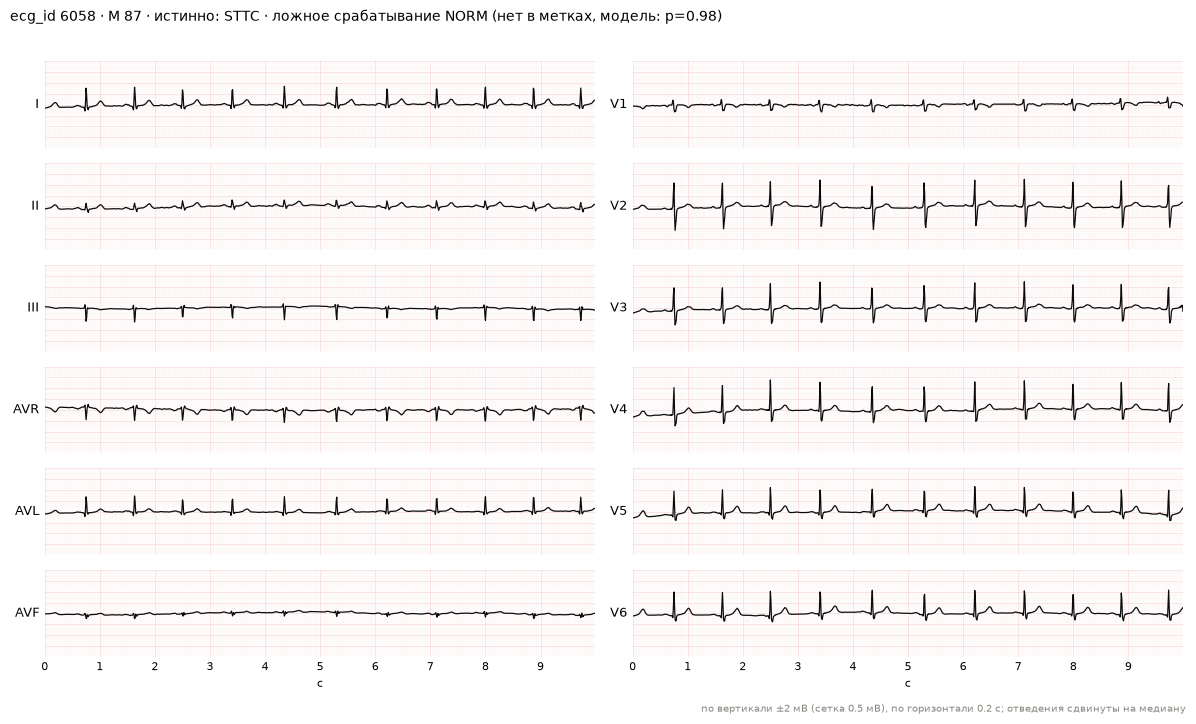

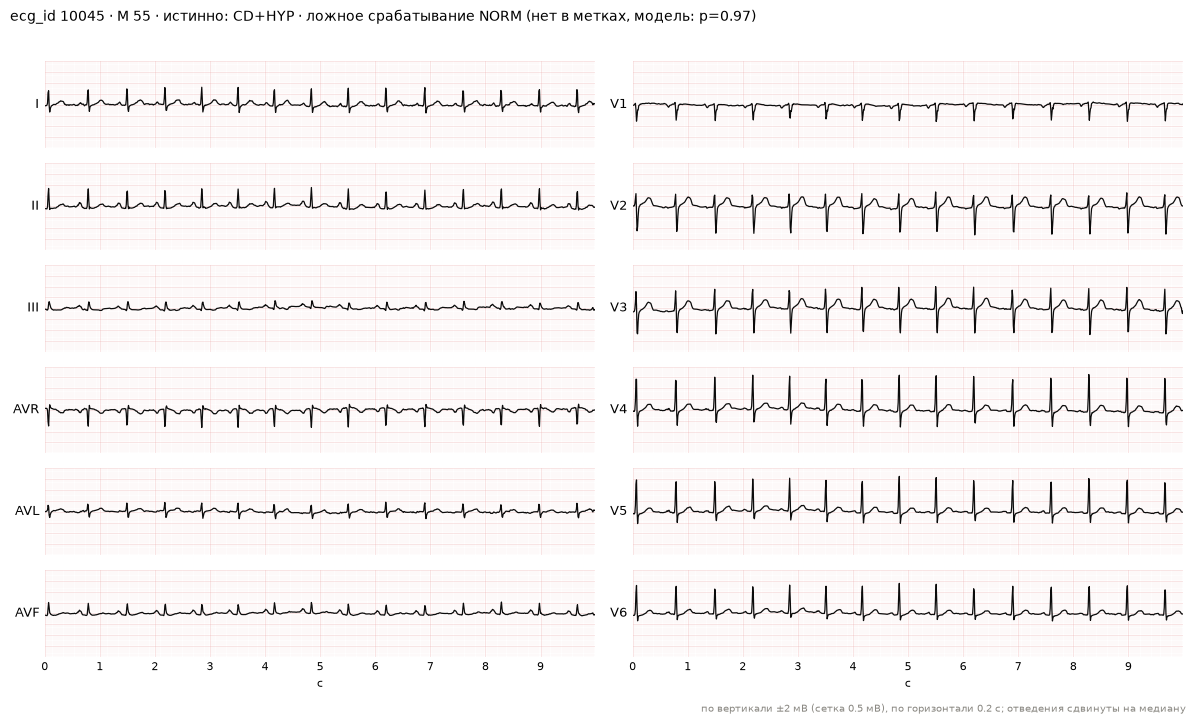


=== NORM: самые уверенные — пропуск ===


,ecg_id,возраст,пол,истинно,предсказано,p(NORM),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,4958,89,Ж,NORM,STTC+HYP,0.005,NORM 0.00 MI 0.11 STTC 0.97 CD 0.16 HYP 0.63,"NORM:100, PAC:0, LPR:0, PVC:0, STACH:0",,premature ventricular contraction(s). premature atrial contraction...
1,10774,26,Ж,NORM,STTC,0.013,NORM 0.01 MI 0.01 STTC 0.99 CD 0.02 HYP 0.16,"NORM:100, INVT:0, STD_:0, STACH:0",,"sinus tachycardia. st segments are depressed in i, ii, v3-6. t wav..."
2,17324,58,М,NORM,STTC+HYP,0.014,NORM 0.01 MI 0.00 STTC 0.95 CD 0.01 HYP 0.88,"NORM:35, SR:0",,sinusrhythmus lagetyp normal unspezifische abnormale st-senkung un...
3,6329,76,М,NORM+STTC,MI+STTC,0.022,NORM 0.02 MI 0.48 STTC 0.85 CD 0.03 HYP 0.20,"NORM:100, NST_:0, PVC:0, STACH:0",,premature ventricular contraction(s). sinus tachycardia. compared ...
4,14235,72,Ж,NORM,STTC,0.046,NORM 0.05 MI 0.09 STTC 0.86 CD 0.04 HYP 0.21,"NORM:100, SR:0",,sinusrhythmus lagetyp normal ekg normal


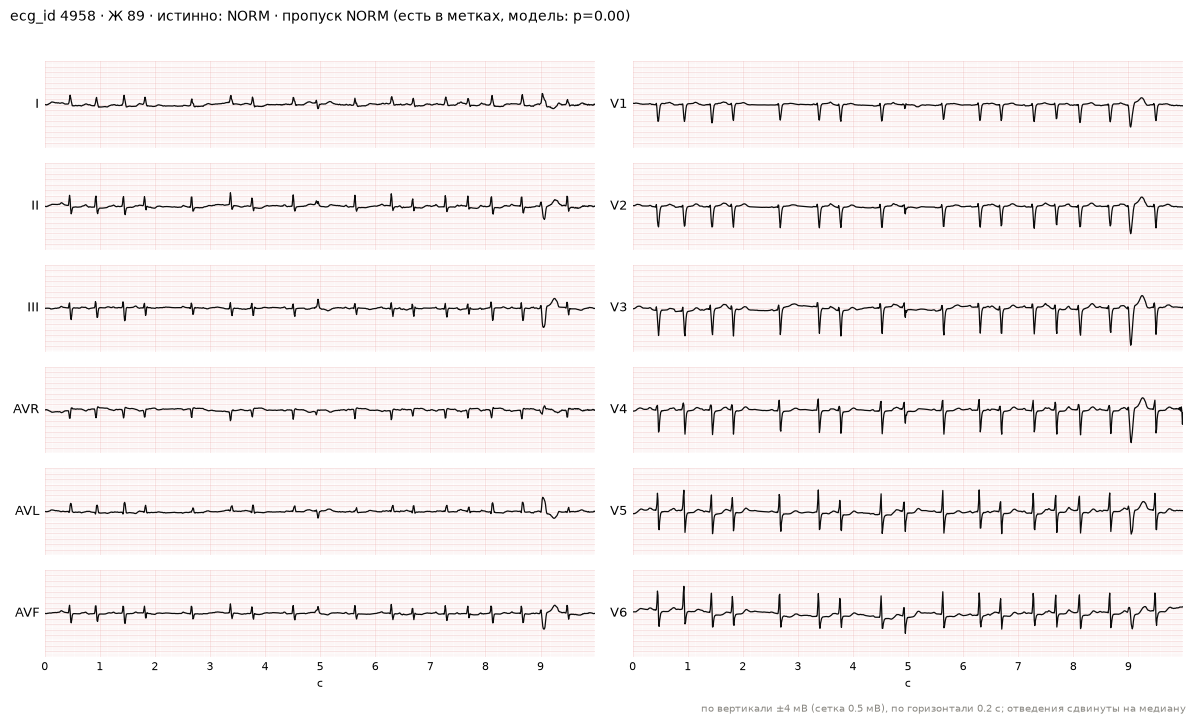

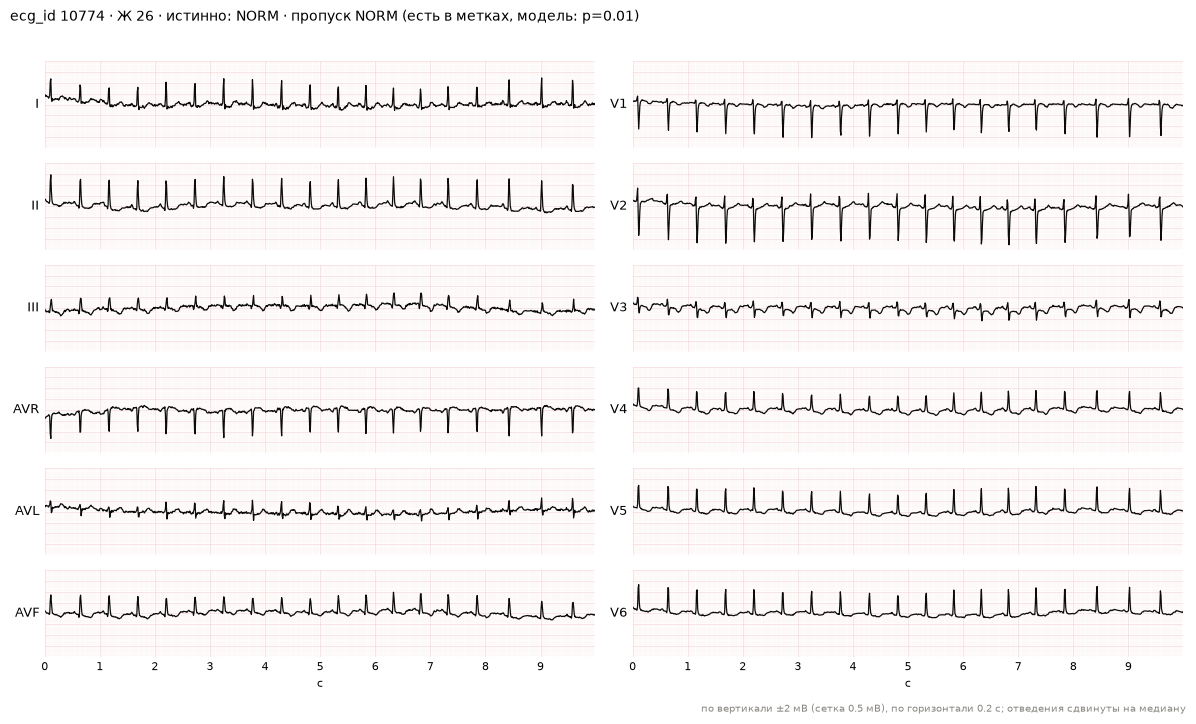

In [18]:
c = "NORM"
j = C.index(c)
for kind, label in (("fp", "ложное срабатывание"), ("fn", "пропуск")):
    top = ea.confident_errors(b.y, b.p_cal, j, kind)
    k_tab, k_plot = cf["top_k_table"], cf["top_k_plots"]
    print(f"\n=== {c}: самые уверенные — {label} ===")
    display(ea.error_table(b, top[:k_tab], j))
    for r in top[:k_plot]:
        m = b.meta.iloc[r]
        what = "нет в метках, модель:" if kind == "fp" else "есть в метках, модель:"
        title = (f"ecg_id {b.ecg_id[r]} · {'М' if m['sex'] == 0 else 'Ж'} {ea.age_label(m['age'])} · "
                 f"истинно: {ea.combo_names(b.y[[r]], C)[0]} · {label} {c} ({what} p={b.p_cal[r, j]:.2f})")
        ea.plot_ecg(b.X[r], b.leads, title, cfg["plots"]["sample_rate"], cfg["plots"]["dpi"])
        plt.show()

**Вывод (NORM).**
*Ложные срабатывания* (модель p≈0.96–0.98 на записях без метки NORM): две записи (11880, 14110) — MI с кодом IMI **likelihood 15**, в отчёте формулировки «möglich» («возможно») и «nicht auszuschli…» («нельзя исключить»);
остальные — CD/HYP с «сильными» кодами (IVCD:100, LAO/LAE:100, WPW:100) и STTC с NST_:100, где в тексте отчёта просто «trace only requested» (ecg_id 6058). Для двух слабых MI-меток картина понятна как неоднозначность метки;
для трёх «сильных» (10045, 11300, 6058) причина неочевидна.
*Пропуски* (метка NORM, модель p≤0.05, предсказывает STTC с p 0.85–0.99): у **10774** метка NORM:100, но текст отчёта говорит о депрессии ST (`st segments are depressed in i, ii, v3-6`) — метка и текст расходятся (кто прав, не оцениваю);
у 17324 метка NORM:35 (слабая) и в отчёте «unspezifische abnormale st-senkung»; у 4958 в отчёте экстрасистолы, но NORM:100; у 14235 (отчёт «ekg normal») и 6329 расхождений в данных не вижу — причина неочевидна.
Форму ЭКГ на графиках я не оцениваю: они приведены, чтобы специалист мог посмотреть записи сам.

### 4.2. MI


=== MI: самые уверенные — ложное срабатывание ===


,ecg_id,возраст,пол,истинно,предсказано,p(MI),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,14059,56,М,CD,MI+CD,0.914,NORM 0.06 MI 0.91 STTC 0.04 CD 0.53 HYP 0.02,"IRBBB:100, SR:0",,sinusrhythmus st-hebung in v2 partieller rechtsschenkelblock termi...
1,4950,77,М,NORM,MI,0.910,NORM 0.06 MI 0.91 STTC 0.09 CD 0.22 HYP 0.04,"NORM:100, PAC:0, NT_:0, SR:0",,premature atrial contraction(s). sinus rhythm. low limb lead volta...
2,8233,61,М,CD,MI,0.881,NORM 0.05 MI 0.88 STTC 0.13 CD 0.14 HYP 0.16,"IVCD:100, QWAVE:0, SR:0",,"sinusrhythmus lagetyp normal q in ii,iii,avf (nicht signifikant) n..."
3,4145,61,М,STTC,MI,0.876,NORM 0.02 MI 0.88 STTC 0.44 CD 0.17 HYP 0.21,"NDT:100, NT_:0, LVOLT:0, SARRH:0",,sinus arrhythmia. low limb lead voltage. non-specific t wave flatt...
4,4733,66,М,CD,MI+CD,0.864,NORM 0.01 MI 0.86 STTC 0.22 CD 0.93 HYP 0.37,"LAFB:100, SR:0",,sinusrhythmus ueberdrehter linkstyp unspezifischer intraventrikulÄ...


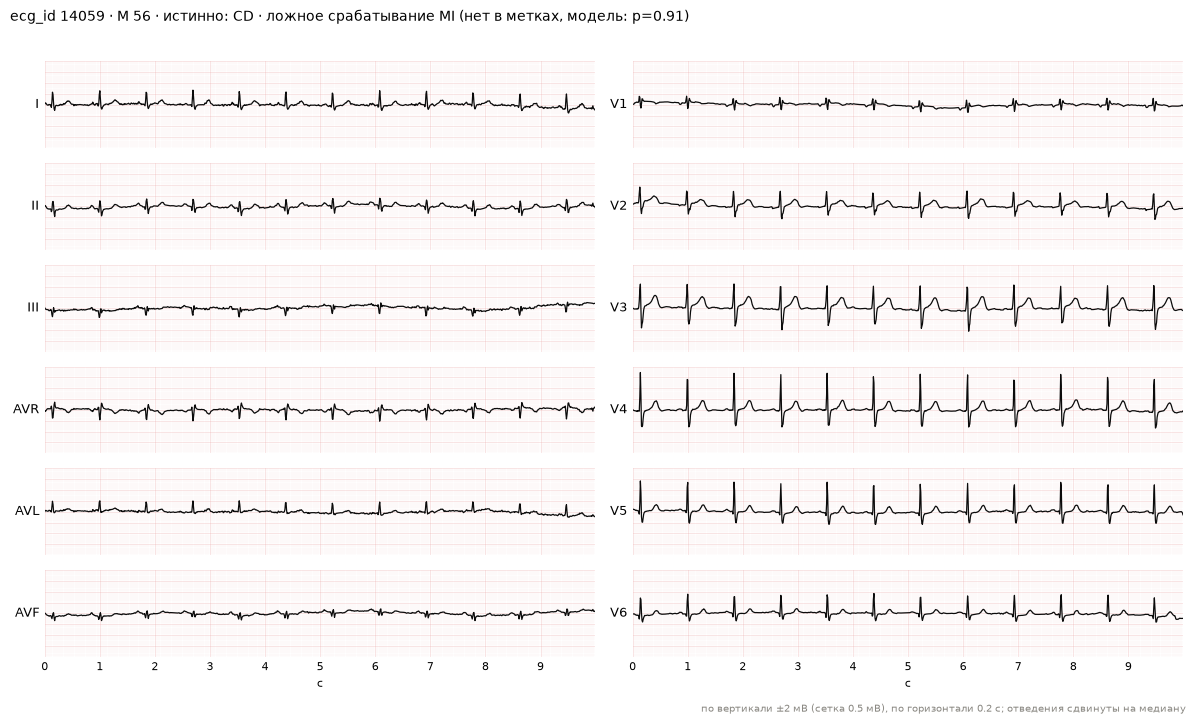

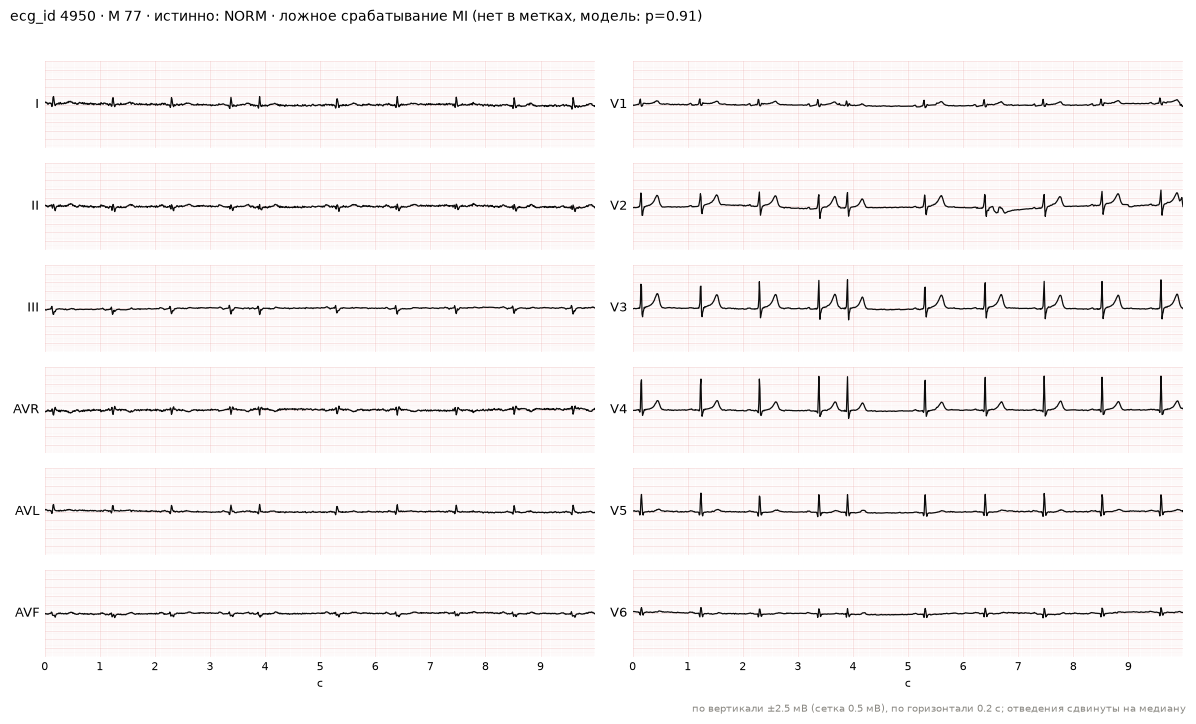


=== MI: самые уверенные — пропуск ===


,ecg_id,возраст,пол,истинно,предсказано,p(MI),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,14202,43,Ж,MI,NORM,0.003,NORM 0.96 MI 0.00 STTC 0.03 CD 0.01 HYP 0.01,"IMI:15, ABQRS:0, SR:0",,sinusrhythmus lagetyp normal qrs(t) abnormal inferiorer myokard...
1,3495,41,Ж,MI+CD,NORM,0.007,NORM 0.69 MI 0.01 STTC 0.06 CD 0.15 HYP 0.06,"LMI:50, IVCD:100, ABQRS:0, SR:0",,sinusrhythmus lagetyp normal unspezifische intraventrikulÄre leitu...
2,11880,53,М,MI,NORM,0.008,NORM 0.96 MI 0.01 STTC 0.01 CD 0.00 HYP 0.01,"IMI:15, ABQRS:0, SR:0",,sinusrhythmus qrs(t) abnormal inferiorer myokardschaden mÖglich
3,14110,64,М,MI,NORM,0.008,NORM 0.96 MI 0.01 STTC 0.01 CD 0.00 HYP 0.00,"IMI:15, ABQRS:0, SR:0",,sinusrhythmus qrs(t) abnormal septaler infarkt nicht auszuschli...
4,18625,72,Ж,MI,NORM,0.010,NORM 0.95 MI 0.01 STTC 0.04 CD 0.06 HYP 0.01,"IMI:15, ABQRS:0, SR:0","baseline_drift, static_noise",sinusrhythmus lagetyp normal qrs(t) abnormal inferiorer infarkt...


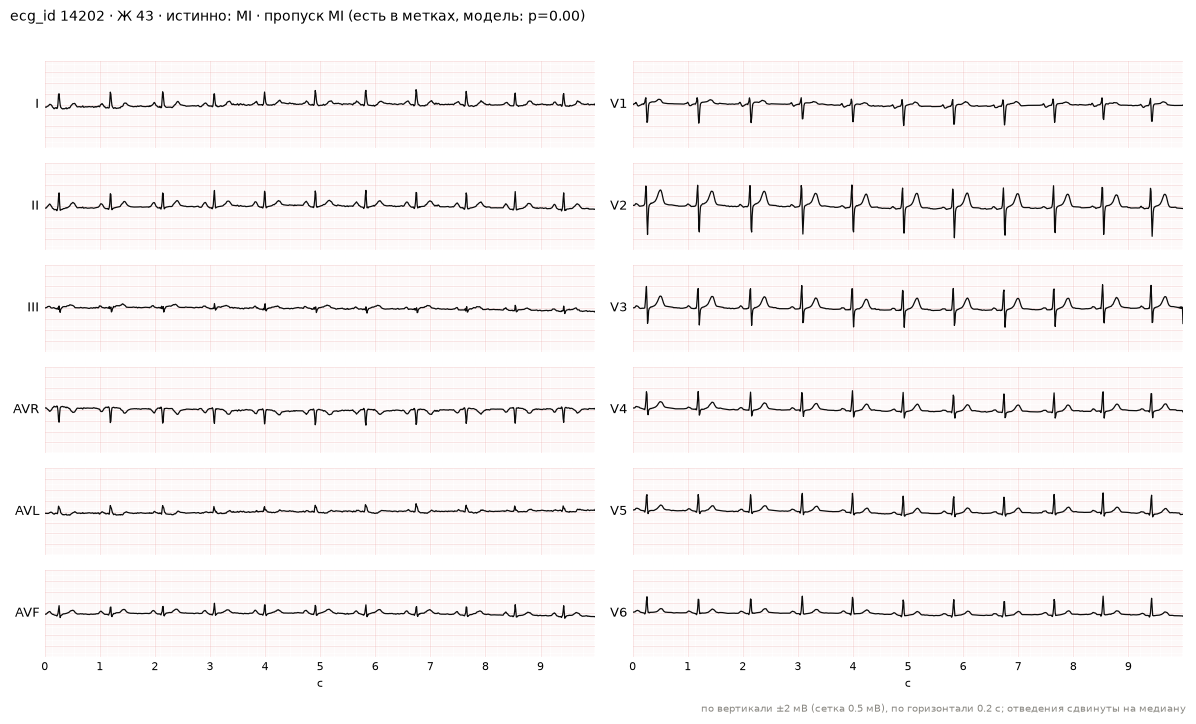

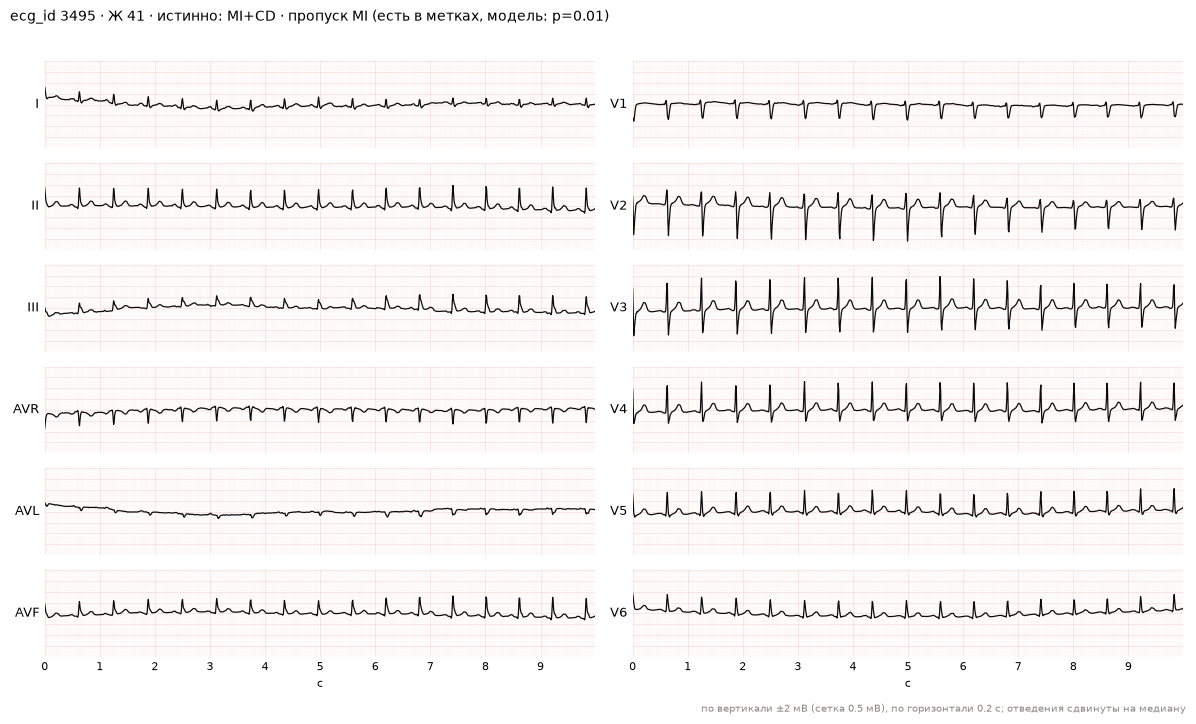

In [19]:
c = "MI"
j = C.index(c)
for kind, label in (("fp", "ложное срабатывание"), ("fn", "пропуск")):
    top = ea.confident_errors(b.y, b.p_cal, j, kind)
    k_tab, k_plot = cf["top_k_table"], cf["top_k_plots"]
    print(f"\n=== {c}: самые уверенные — {label} ===")
    display(ea.error_table(b, top[:k_tab], j))
    for r in top[:k_plot]:
        m = b.meta.iloc[r]
        what = "нет в метках, модель:" if kind == "fp" else "есть в метках, модель:"
        title = (f"ecg_id {b.ecg_id[r]} · {'М' if m['sex'] == 0 else 'Ж'} {ea.age_label(m['age'])} · "
                 f"истинно: {ea.combo_names(b.y[[r]], C)[0]} · {label} {c} ({what} p={b.p_cal[r, j]:.2f})")
        ea.plot_ecg(b.X[r], b.leads, title, cfg["plots"]["sample_rate"], cfg["plots"]["dpi"])
        plt.show()

**Вывод (MI).**
*Пропуски* — основная проблема: **у четырёх из пяти самых уверенных пропусков (14202, 11880, 14110, 18625) метка — IMI с likelihood 15**, в отчётах двух из них — «inferiorer myokardschaden möglich» («возможно») и «septaler infarkt nicht auszuschli…» («нельзя исключить»);
модель ставит NORM с p=0.95–0.96, p(MI)≤0.01. Пятая запись (3495): LMI:50 + IVCD:100, NORM 0.69. Это согласуется с таблицей слабых меток (41 из 52 уверенных пропусков — likelihood < 100).
Является ли такая метка настоящим инфарктом, из данных не видно.
*Ложные срабатывания* уверенные редки (10 на весь val). В топ-5 у записей с метками CD/NORM/STTC модель даёт p(MI)=0.86–0.91; в отчётах 14059 упомянут `st-hebung in v2` («подъём ST в V2»), у 8233 — `q in ii,iii,avf (nicht signifikant)` («Q в II, III, aVF, не значим»), у остальных ничего очевидного нет. Верно ли модель «видит» MI там — не знаю.

### 4.3. STTC


=== STTC: самые уверенные — ложное срабатывание ===


,ecg_id,возраст,пол,истинно,предсказано,p(STTC),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,1451,69,Ж,HYP,STTC+HYP,0.993,NORM 0.00 MI 0.03 STTC 0.99 CD 0.02 HYP 1.00,"LVH:100, SR:0",,sinusrytm vÄnster kammarhypertrofi
1,10774,26,Ж,NORM,STTC,0.988,NORM 0.01 MI 0.01 STTC 0.99 CD 0.02 HYP 0.16,"NORM:100, INVT:0, STD_:0, STACH:0",,"sinus tachycardia. st segments are depressed in i, ii, v3-6. t wav..."
2,10306,73,М,CD,STTC,0.979,NORM 0.01 MI 0.02 STTC 0.98 CD 0.35 HYP 0.17,"PSVT:100, IRBBB:100",,supraventr. tachyarrhythmie lagetyp normal part. rsb
3,3642,60,М,HYP,STTC+HYP,0.975,NORM 0.00 MI 0.03 STTC 0.98 CD 0.05 HYP 0.89,"LVH:50, SBRAD:0",,sinusbradykardie p-verbreiterung lagetyp normal linkshypertrophie ...
4,4958,89,Ж,NORM,STTC+HYP,0.965,NORM 0.00 MI 0.11 STTC 0.97 CD 0.16 HYP 0.63,"NORM:100, PAC:0, LPR:0, PVC:0, STACH:0",,premature ventricular contraction(s). premature atrial contraction...


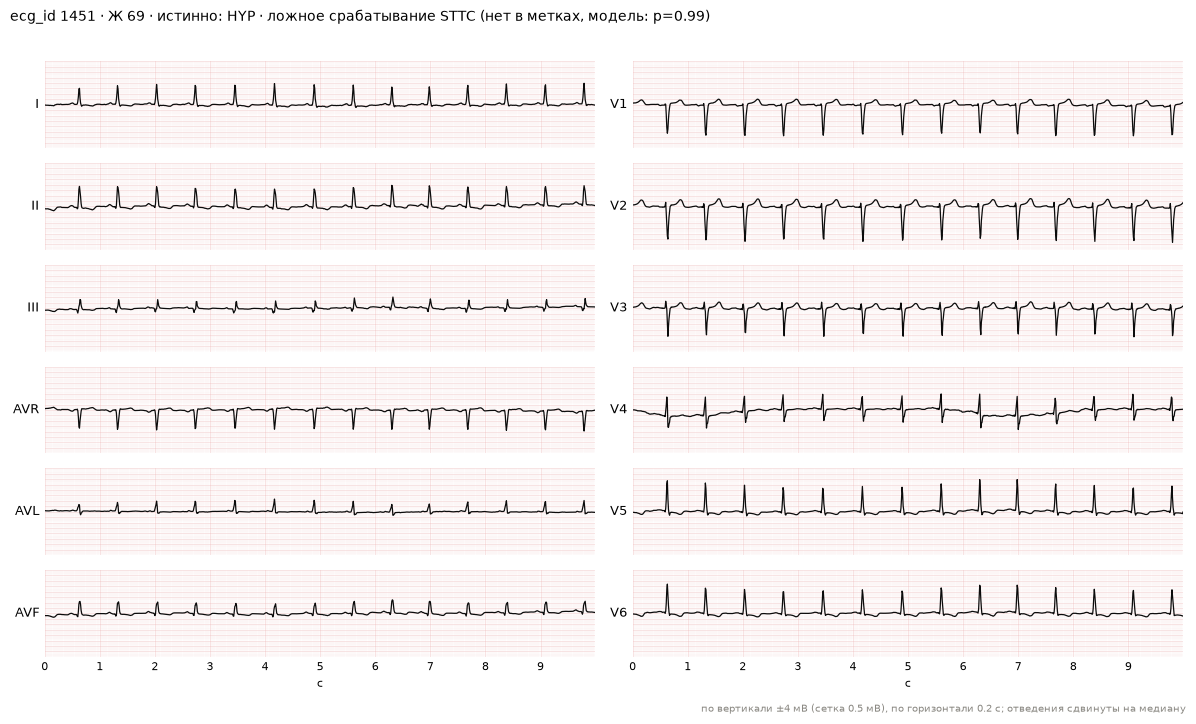

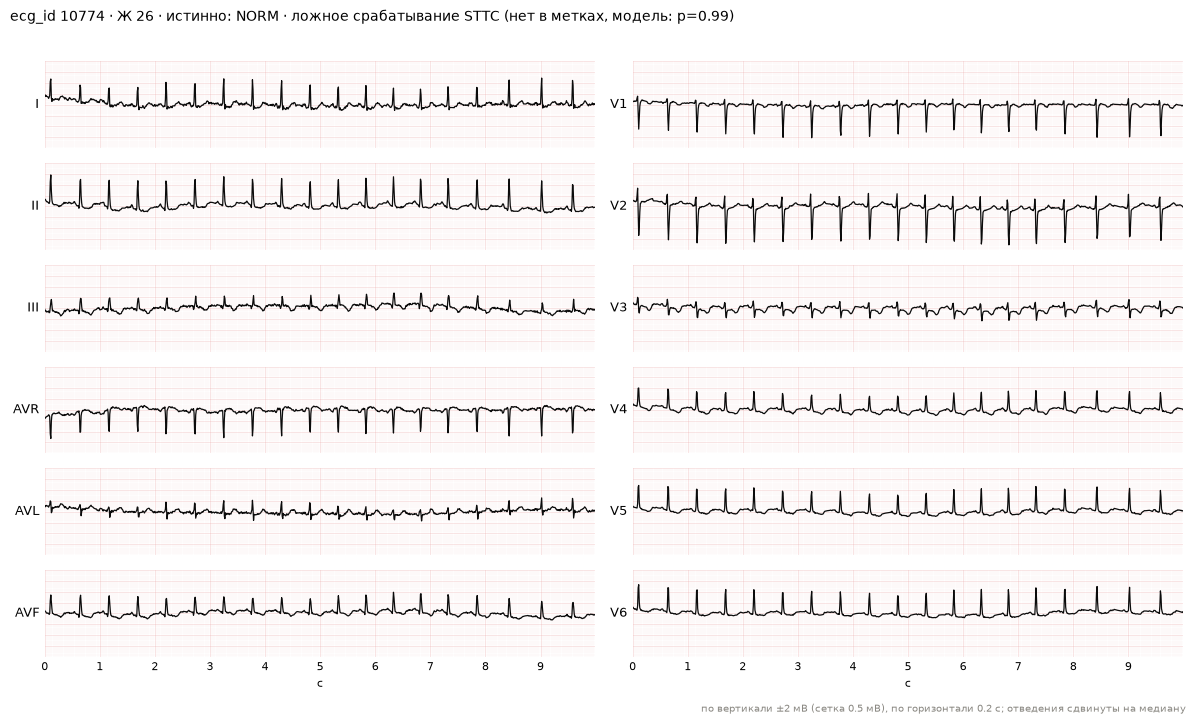


=== STTC: самые уверенные — пропуск ===


,ecg_id,возраст,пол,истинно,предсказано,p(STTC),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,6058,87,М,STTC,NORM,0.006,NORM 0.98 MI 0.01 STTC 0.01 CD 0.01 HYP 0.00,NST_:100,,trace only requested.
1,13830,61,М,STTC,NORM,0.037,NORM 0.91 MI 0.00 STTC 0.04 CD 0.01 HYP 0.05,"ISCIN:50, STD_:0, SR:0",baseline_drift,"sinus rhythm. st segments are depressed in ii, iii, avf. non-speci..."
2,20791,47,М,STTC,NORM+MI,0.053,NORM 0.62 MI 0.25 STTC 0.05 CD 0.02 HYP 0.02,"NST_:100, SR:0",,sinusrhythmus lagetyp normal unspezifisch abnormes st-t (hebung) s...
3,12138,61,М,MI+STTC+CD,MI,0.058,NORM 0.00 MI 1.00 STTC 0.06 CD 0.04 HYP 0.01,"ILMI:100, IRBBB:100, ISCLA:100, PVC:100, STACH:0",,llt sinustachykardie sves ( vorhof ) Über 5/min. partieller rechts...
4,12994,57,М,MI+STTC,NORM,0.061,NORM 0.56 MI 0.21 STTC 0.06 CD 0.04 HYP 0.19,"AMI:50, INJAL:35, ISCIN:100, SBRAD:0",,"sinusbradykardie linkstyp t abnormal, wahrscheinlich anterolate..."


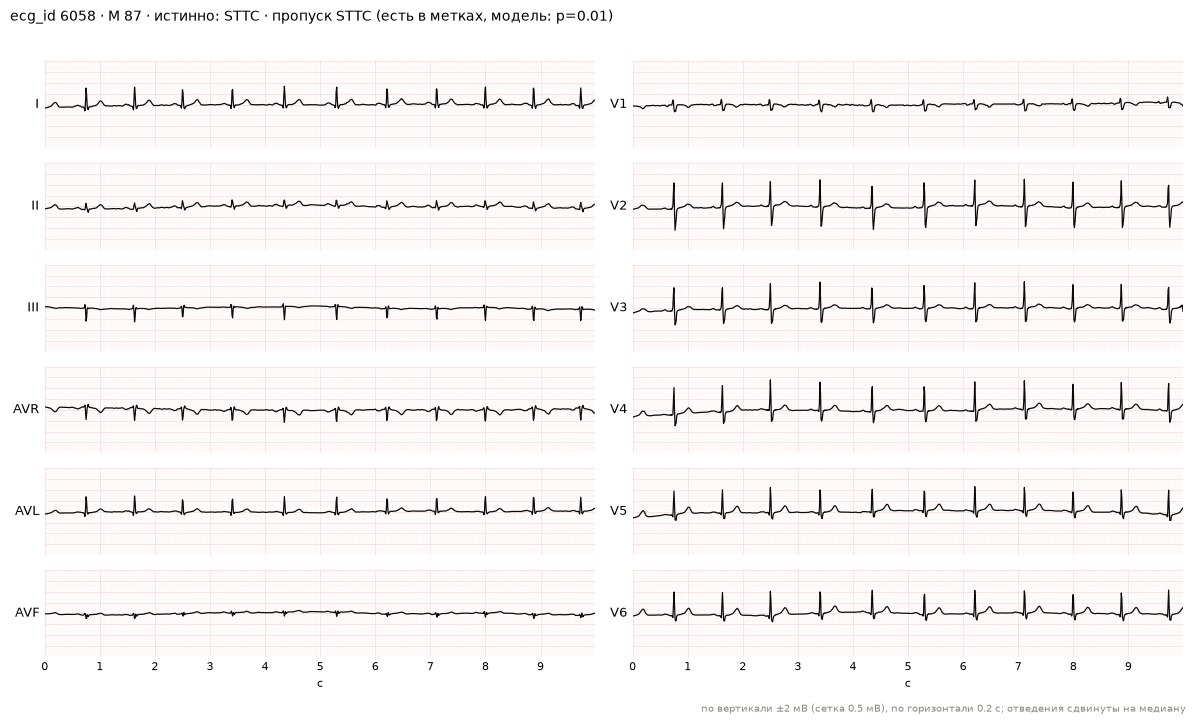

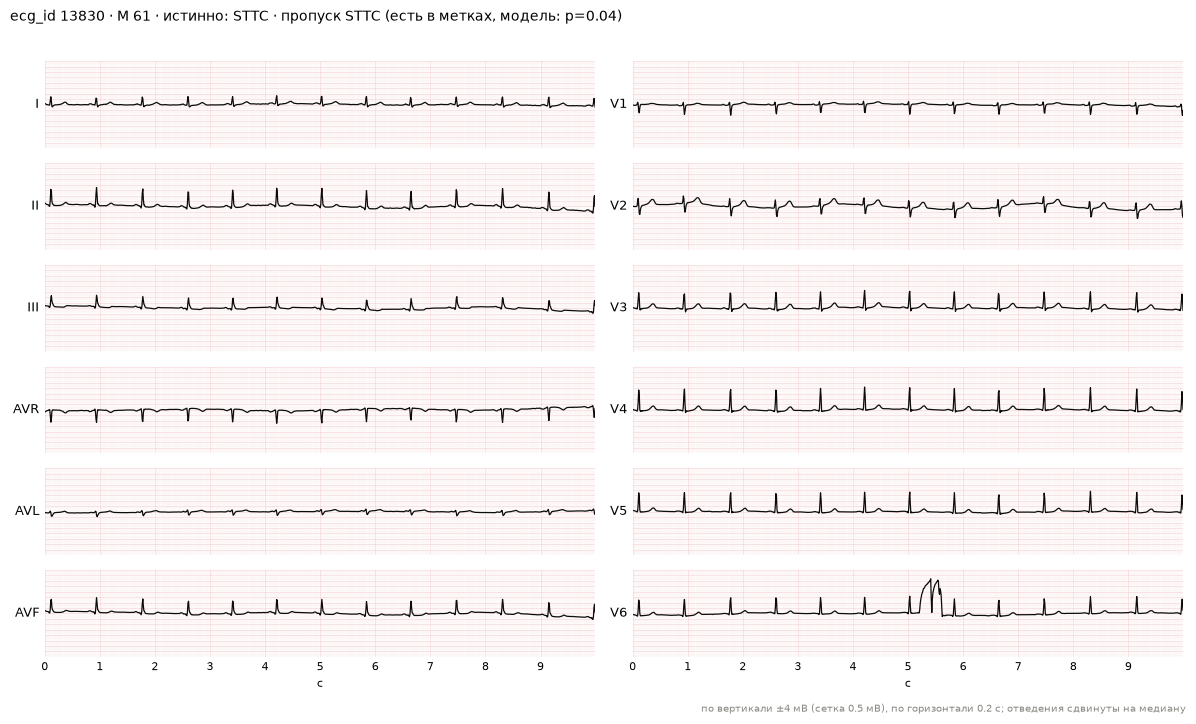

In [20]:
c = "STTC"
j = C.index(c)
for kind, label in (("fp", "ложное срабатывание"), ("fn", "пропуск")):
    top = ea.confident_errors(b.y, b.p_cal, j, kind)
    k_tab, k_plot = cf["top_k_table"], cf["top_k_plots"]
    print(f"\n=== {c}: самые уверенные — {label} ===")
    display(ea.error_table(b, top[:k_tab], j))
    for r in top[:k_plot]:
        m = b.meta.iloc[r]
        what = "нет в метках, модель:" if kind == "fp" else "есть в метках, модель:"
        title = (f"ecg_id {b.ecg_id[r]} · {'М' if m['sex'] == 0 else 'Ж'} {ea.age_label(m['age'])} · "
                 f"истинно: {ea.combo_names(b.y[[r]], C)[0]} · {label} {c} ({what} p={b.p_cal[r, j]:.2f})")
        ea.plot_ecg(b.X[r], b.leads, title, cfg["plots"]["sample_rate"], cfg["plots"]["dpi"])
        plt.show()

**Вывод (STTC).**
*Ложные срабатывания* (p до 0.99): две записи (1451, 3642) — HYP с кодом LVH, где модель предсказывает STTC+HYP — это согласуется с частым сочетанием STTC+HYP в метках (см. `01_eda`), но есть ли в этих ЭКГ изменения ST-T, я не знаю;
запись **10774** — метка NORM:100, при этом в отчёте описана депрессия ST (та же запись, что в NORM-пропусках: метка и отчёт расходятся); 10306 (CD) и 4958 (NORM:100, экстрасистолы в отчёте) — причина неочевидна.
*Пропуски* редки (уверенных 8). Среди пяти самых уверенных — коды NST_:100 и ISCIN:50 (один с `baseline_drift`), запись 6058 — снова «trace only requested»; у 12138 метка MI+STTC+CD, а модель даёт MI (p=1.00), но STTC лишь 0.06 и CD 0.04.
Это не противоречит слабой полноте кода NDT (0.76) из раздела 2; чем он отличается для модели, неочевидно.

### 4.4. CD


=== CD: самые уверенные — ложное срабатывание ===


,ecg_id,возраст,пол,истинно,предсказано,p(CD),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,5006,68,М,STTC,STTC+CD,0.926,NORM 0.01 MI 0.05 STTC 0.75 CD 0.93 HYP 0.06,"NDT:100, SR:0",static_noise,sinusrhythmus linkstyp unspezifisches abnormales t
1,5863,70,М,MI,MI+CD,0.923,NORM 0.01 MI 0.90 STTC 0.47 CD 0.92 HYP 0.42,"ALMI:100, ASMI:100, SR:0",static_noise,sinusrhythmus p-sinistrocardiale ueberdrehter linkstyp linksschenk...
2,12490,77,Ж,MI,MI+STTC+CD,0.922,NORM 0.00 MI 0.60 STTC 0.78 CD 0.92 HYP 0.16,"ILMI:100, ASMI:100, ABQRS:0, AFIB:0",baseline_drift,vorhofflimmern/-flattern lagetyp normal periphere niederspannung q...
3,4044,55,М,MI,NORM+CD,0.869,NORM 0.49 MI 0.04 STTC 0.06 CD 0.87 HYP 0.03,"IMI:100, ABQRS:0, SR:0",static_noise,sinusrhythmus linkstyp qrs(t) abnorm inferiorer infarkt mÖglich
4,6816,90+,Ж,STTC,CD+HYP,0.843,NORM 0.00 MI 0.01 STTC 0.45 CD 0.84 HYP 0.79,"ISCAS:100, SR:0",baseline_drift,"sinusrytm vÄnster el-axel t-fÖrÄndring, sÅsom vid anterior myok..."


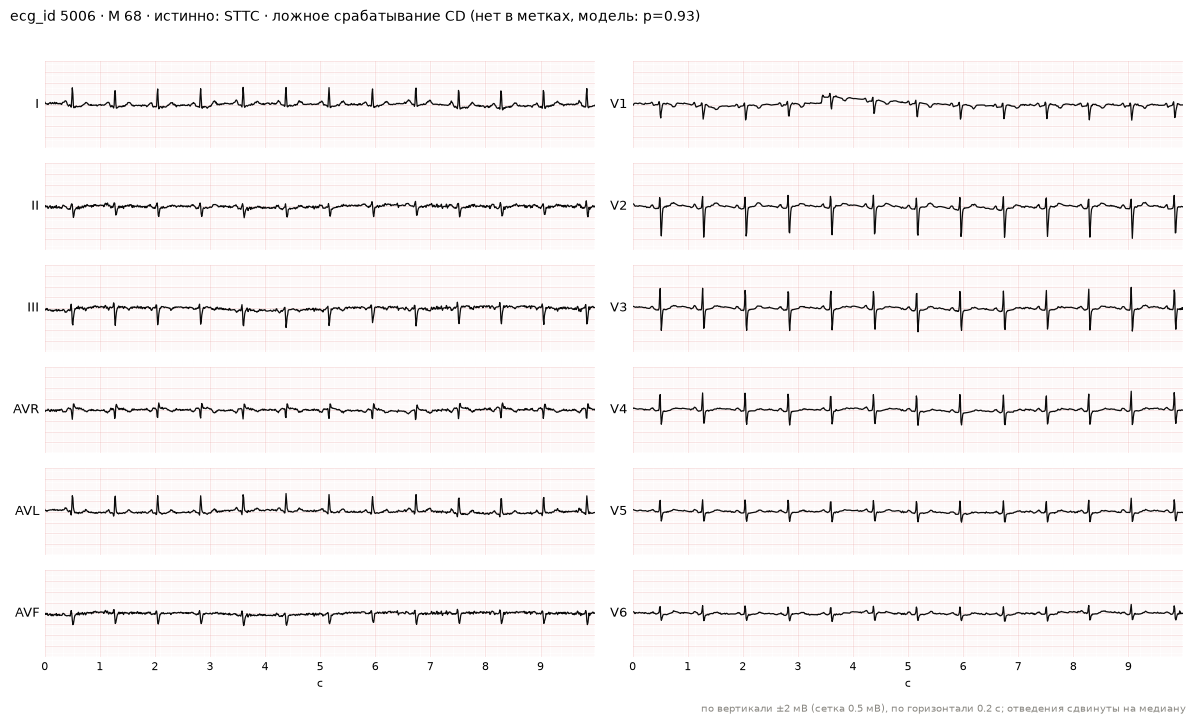

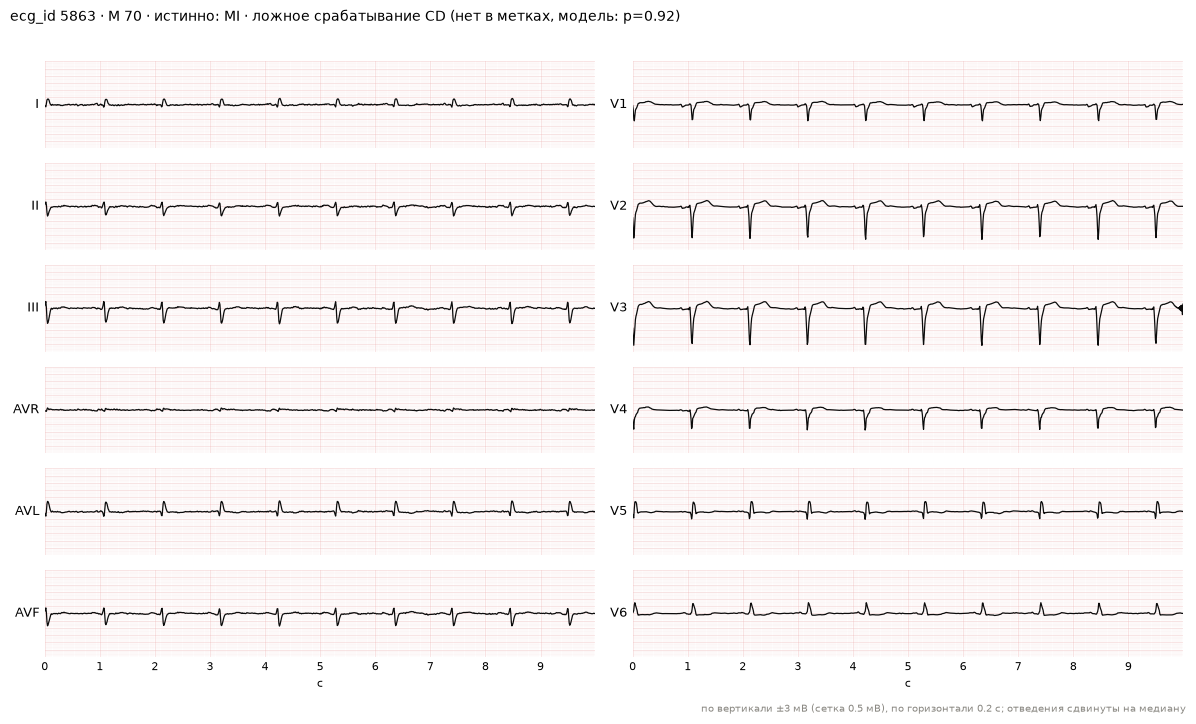


=== CD: самые уверенные — пропуск ===


,ecg_id,возраст,пол,истинно,предсказано,p(CD),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,7419,18,Ж,CD,NORM,0.004,NORM 0.89 MI 0.02 STTC 0.05 CD 0.00 HYP 0.01,"LPFB:100, SR:0",,sinusrhythmus rechtstyp linksposteriorer hemiblock
1,10045,55,М,CD+HYP,NORM,0.004,NORM 0.97 MI 0.00 STTC 0.02 CD 0.00 HYP 0.02,"LAO/LAE:100, IVCD:100, STD_:0, SR:0",,"sinusrhythmus lagetyp normal intraventr. leitungsstoerung ii, iii,..."
2,7945,77,Ж,STTC+CD+HYP,STTC+HYP,0.008,NORM 0.00 MI 0.02 STTC 0.97 CD 0.01 HYP 0.53,"NDT:100, IVCD:100, LAO/LAE:35, LOWT:0, SR:0",,sinus rhythm. possible left atrial enlargement. t waves are low or...
3,18549,56,Ж,CD,NORM,0.009,NORM 0.93 MI 0.06 STTC 0.02 CD 0.01 HYP 0.00,"IVCD:100, SR:0",,sinusrhythmus lagetyp normal intraventr. leitungsstoerung avf schl...
4,1205,45,М,STTC+CD,STTC+HYP,0.013,NORM 0.05 MI 0.07 STTC 0.78 CD 0.01 HYP 0.63,"NDT:100, IVCD:100, SR:0","static_noise, burst_noise",sinusrhythmus linkstyp unspezifisches abnormales t


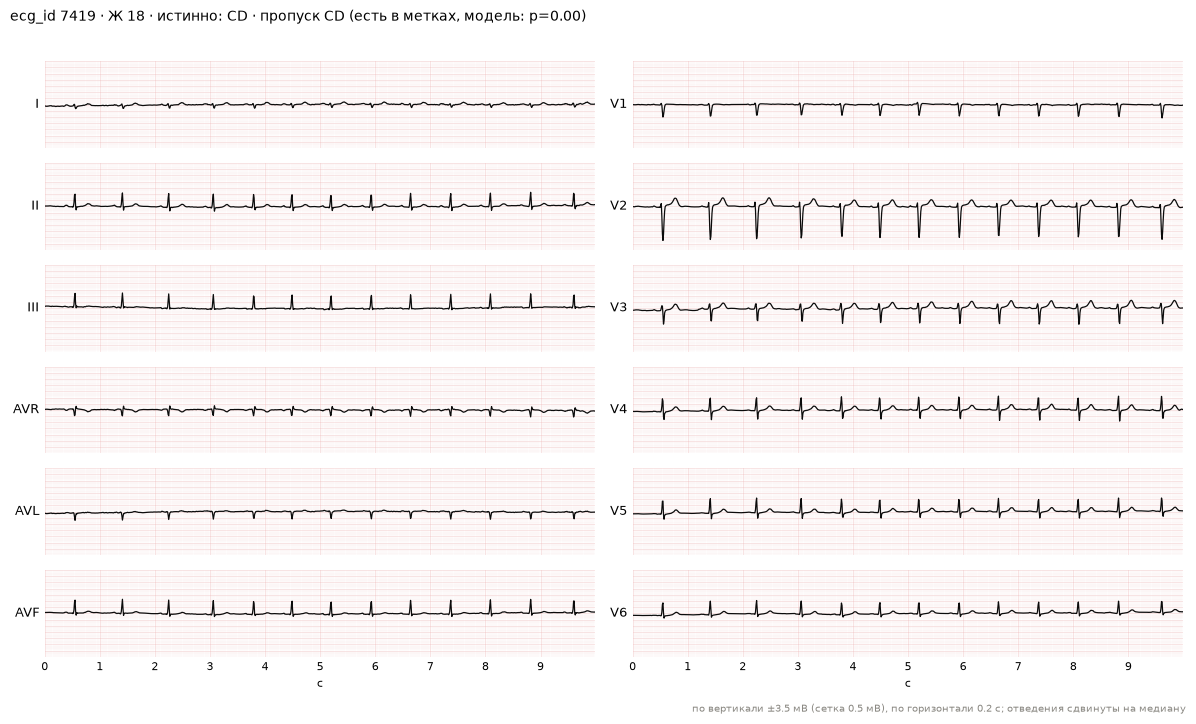

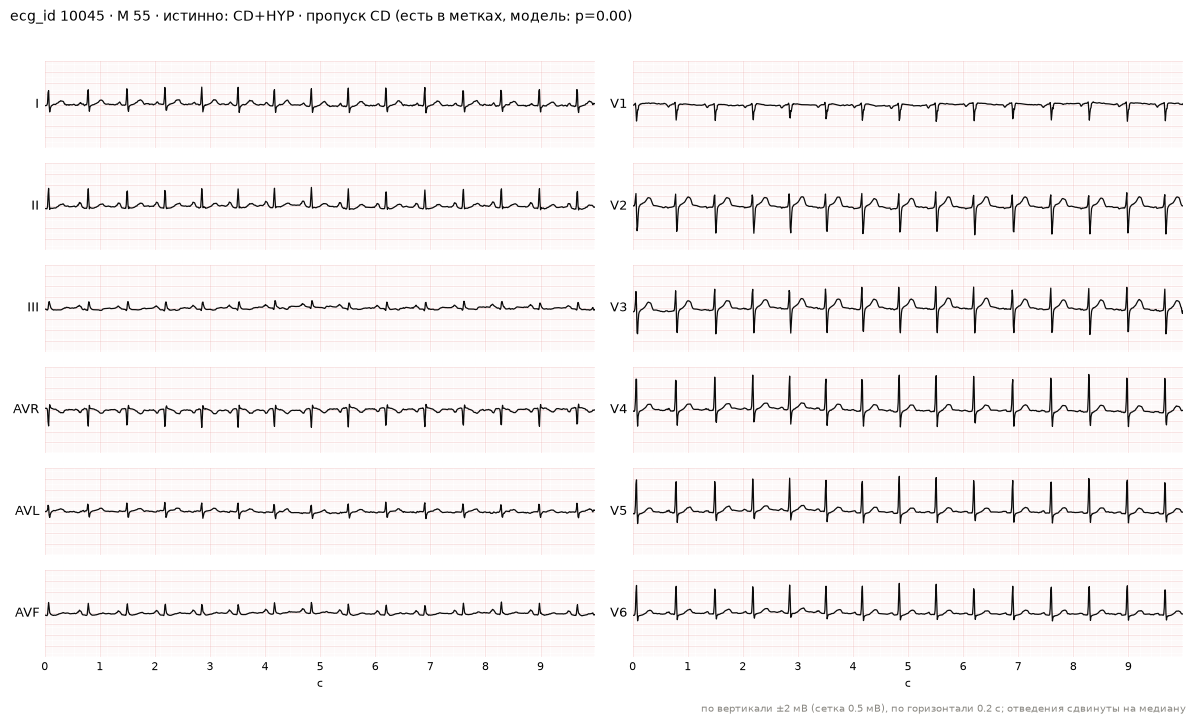

In [21]:
c = "CD"
j = C.index(c)
for kind, label in (("fp", "ложное срабатывание"), ("fn", "пропуск")):
    top = ea.confident_errors(b.y, b.p_cal, j, kind)
    k_tab, k_plot = cf["top_k_table"], cf["top_k_plots"]
    print(f"\n=== {c}: самые уверенные — {label} ===")
    display(ea.error_table(b, top[:k_tab], j))
    for r in top[:k_plot]:
        m = b.meta.iloc[r]
        what = "нет в метках, модель:" if kind == "fp" else "есть в метках, модель:"
        title = (f"ecg_id {b.ecg_id[r]} · {'М' if m['sex'] == 0 else 'Ж'} {ea.age_label(m['age'])} · "
                 f"истинно: {ea.combo_names(b.y[[r]], C)[0]} · {label} {c} ({what} p={b.p_cal[r, j]:.2f})")
        ea.plot_ecg(b.X[r], b.leads, title, cfg["plots"]["sample_rate"], cfg["plots"]["dpi"])
        plt.show()

**Вывод (CD).**
*Ложные срабатывания* (p=0.84–0.93; 8 уверенных на весь val): **у всех пяти записей в таблице есть пометка о шуме или дрейфе** (`static_noise` ×3, `baseline_drift` ×2) — всего 6 из 8 уверенных ЛС (раздел 4, проверка шума; на графике записи 5006 видна высокочастотная «рябь» в отведениях II, III, aVF, что согласуется с пометкой).
Истинные метки там — MI или STTC. Что именно в шумной записи заставляет модель увидеть CD, не знаю; для этого нужна проверка на большем числе записей (n=8).
*Пропуски* (p(CD)≤0.013): у четырёх из пяти есть **IVCD** (10045, 18549, 1205, 7945), у 7419 — LPFB; модель ставит NORM (0.89–0.97) или STTC+HYP. Это совпадает с самой слабой кодом CD (IVCD, recall 0.42), метки при этом «сильные» (likelihood 100).
Почему IVCD модель находит плохо, неочевидно. Запись 10045 — один и тот же ECG с кодами LAO/LAE:100 и IVCD:100, он же в пропусках HYP и в ложных NORM: модель видит в нём норму с p=0.97.

### 4.5. HYP


=== HYP: самые уверенные — ложное срабатывание ===


,ecg_id,возраст,пол,истинно,предсказано,p(HYP),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,7653,74,М,MI,MI+STTC+HYP,0.990,NORM 0.00 MI 0.86 STTC 0.94 CD 0.04 HYP 0.99,"ASMI:100, IMI:100, PVC:100, ABQRS:0, AFIB:0",,ventrikulÄre extrasystole(n) vorhofflimmern/-flattern ueberdrehter...
1,18273,77,Ж,STTC,STTC+HYP,0.941,NORM 0.00 MI 0.03 STTC 0.99 CD 0.02 HYP 0.94,"ISC_:100, DIG:100, STD_:0, AFIB:0",,"atrial fibrillation. st segments are depressed in i, ii, avl, avf,..."
2,10452,45,М,MI+CD,MI+STTC+HYP,0.922,NORM 0.01 MI 0.34 STTC 0.67 CD 0.19 HYP 0.92,"IMI:100, INJAL:100, IVCD:100, SR:0",,sinusrhythmus verdacht auf p-sinistrocardiale linkstyp unspezifisc...
3,3531,81,Ж,STTC,STTC+HYP,0.912,NORM 0.00 MI 0.03 STTC 0.98 CD 0.02 HYP 0.91,"ISCLA:100, PAC:0, SR:0",,premature atrial contraction(s). sinus rhythm. t waves are flat in...
4,15805,75,М,STTC+CD,STTC+CD+HYP,0.909,NORM 0.00 MI 0.08 STTC 0.97 CD 0.49 HYP 0.91,"ISCAL:100, 1AVB:100, SR:0",baseline_drift,"sinusrytm a-v block i vÄnster el-axel st-t sÄnkning, sÅsom vid ..."


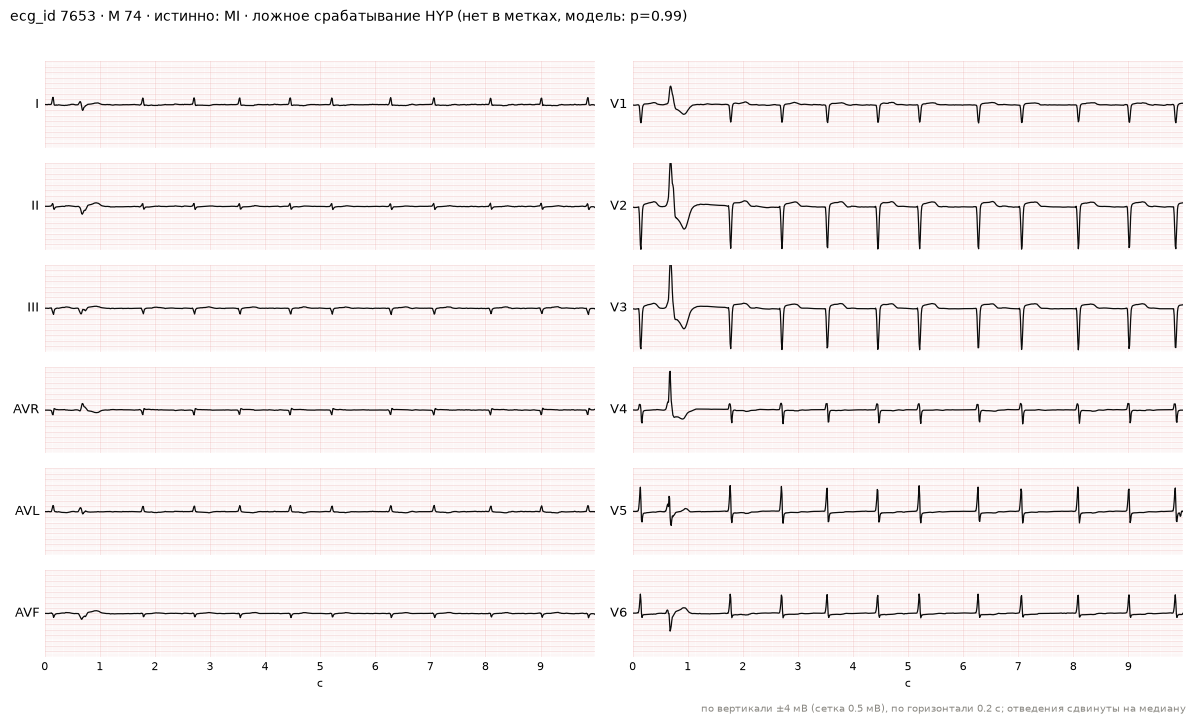

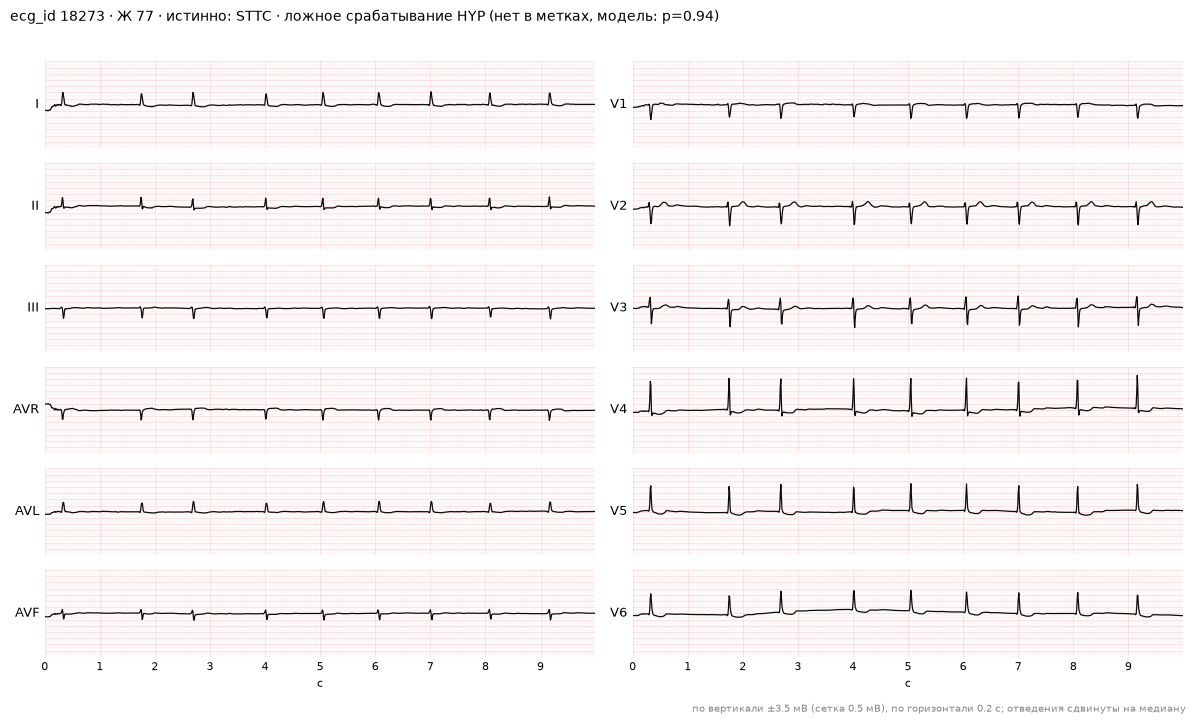


=== HYP: самые уверенные — пропуск ===


,ecg_id,возраст,пол,истинно,предсказано,p(HYP),p по классам,коды SCP (likelihood),пометки о шуме,отчёт (исходный текст)
0,8251,54,М,CD+HYP,NORM,0.003,NORM 0.95 MI 0.01 STTC 0.00 CD 0.10 HYP 0.00,"LAO/LAE:100, 1AVB:100, SBRAD:0",,llt sinusbradykardie mÖgliche links-vorhofsÜberbelastung av-block ...
1,15995,49,М,CD+HYP,NORM,0.007,NORM 0.90 MI 0.01 STTC 0.01 CD 0.20 HYP 0.01,"RVH:35, IRBBB:100, SR:0",,sinus rhythm. incomplete right bundle branch block. otherwise norm...
2,10045,55,М,CD+HYP,NORM,0.017,NORM 0.97 MI 0.00 STTC 0.02 CD 0.00 HYP 0.02,"LAO/LAE:100, IVCD:100, STD_:0, SR:0",,"sinusrhythmus lagetyp normal intraventr. leitungsstoerung ii, iii,..."
3,15775,44,Ж,NORM+HYP,NORM,0.017,NORM 0.86 MI 0.07 STTC 0.03 CD 0.07 HYP 0.02,"NORM:100, RAO/RAE:50, LVOLT:0, SR:0",,sinus rhythm. low limb lead voltage. no definite pathology.
4,4986,63,М,HYP,NORM,0.021,NORM 0.88 MI 0.11 STTC 0.03 CD 0.03 HYP 0.02,"LAO/LAE:50, SBRAD:0",,sinusbradykardie lagetyp normal vorhoflÜberlastung links mÖglich s...


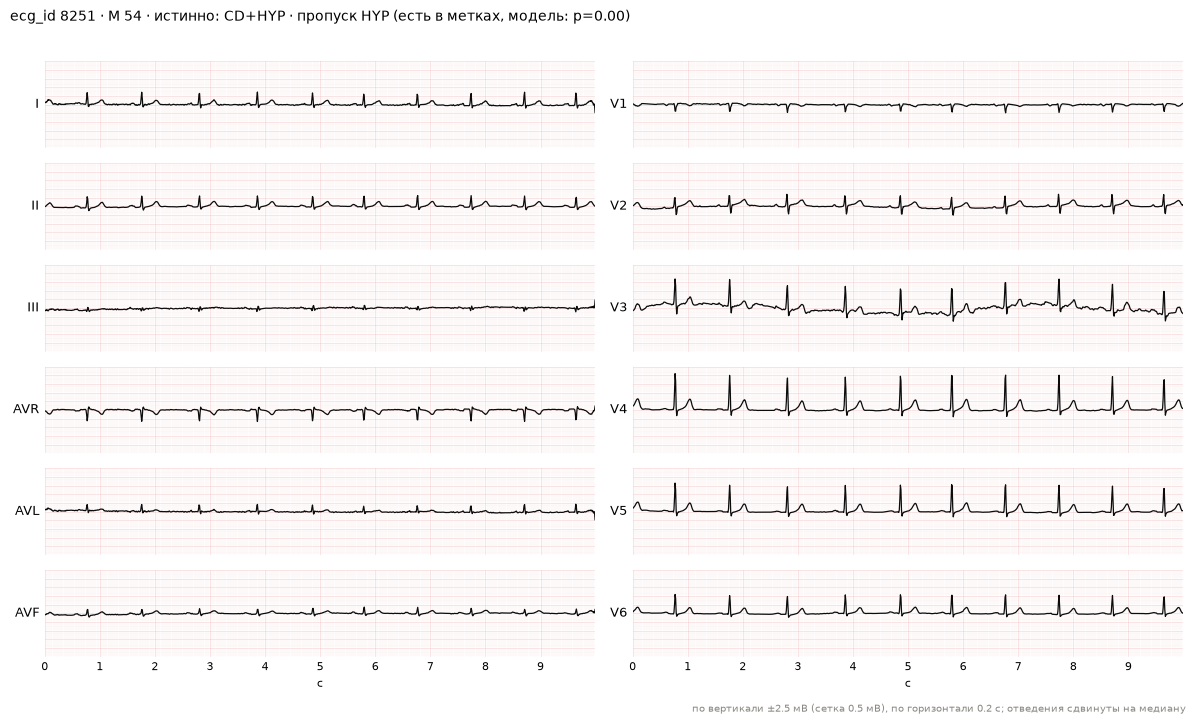

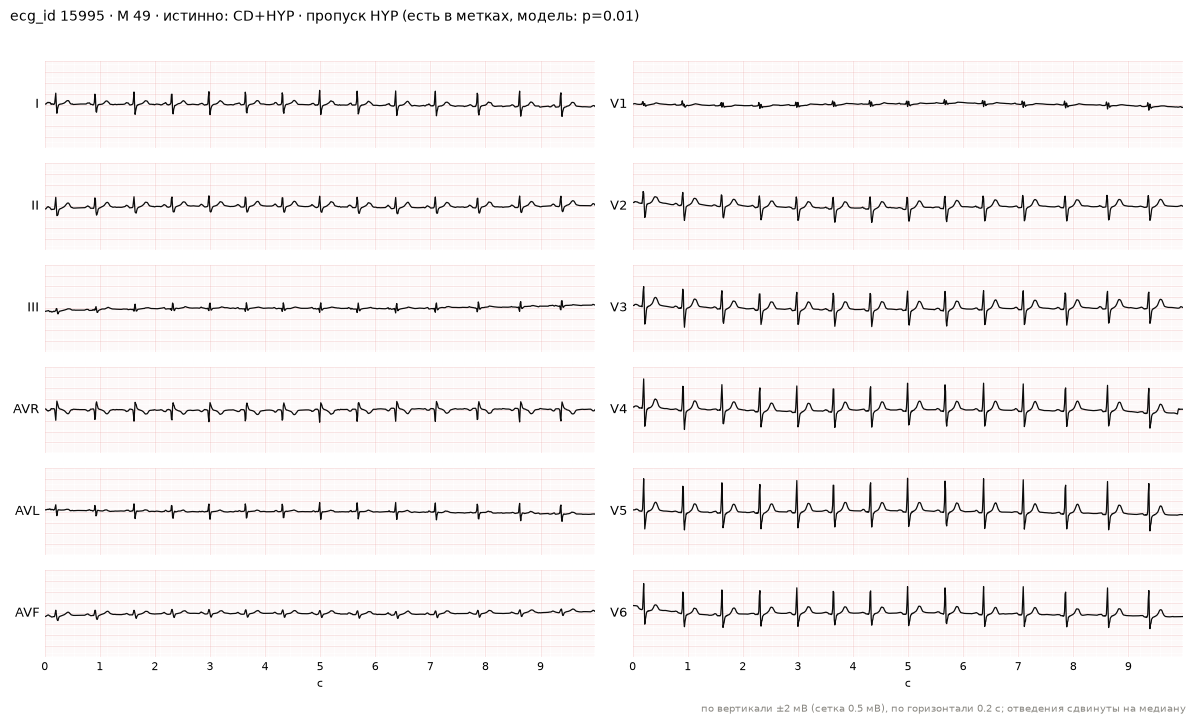

In [22]:
c = "HYP"
j = C.index(c)
for kind, label in (("fp", "ложное срабатывание"), ("fn", "пропуск")):
    top = ea.confident_errors(b.y, b.p_cal, j, kind)
    k_tab, k_plot = cf["top_k_table"], cf["top_k_plots"]
    print(f"\n=== {c}: самые уверенные — {label} ===")
    display(ea.error_table(b, top[:k_tab], j))
    for r in top[:k_plot]:
        m = b.meta.iloc[r]
        what = "нет в метках, модель:" if kind == "fp" else "есть в метках, модель:"
        title = (f"ecg_id {b.ecg_id[r]} · {'М' if m['sex'] == 0 else 'Ж'} {ea.age_label(m['age'])} · "
                 f"истинно: {ea.combo_names(b.y[[r]], C)[0]} · {label} {c} ({what} p={b.p_cal[r, j]:.2f})")
        ea.plot_ecg(b.X[r], b.leads, title, cfg["plots"]["sample_rate"], cfg["plots"]["dpi"])
        plt.show()

**Вывод (HYP).**
*Ложные срабатывания* (p=0.91–0.99): у всех пяти записей другие патологии (MI, STTC, MI+CD), и **у всех пяти модель одновременно ставит STTC (p от 0.67 до 0.99)** — выглядит как путаница STTC↔HYP, о которой говорит и раздел 2 (13% «чистых» STTC получают HYP). Почему так — неочевидно.
*Пропуски* (p(HYP)≤0.02, модель предсказывает NORM 0.86–0.97): у четырёх из пяти метка HYP идёт из **предсердных кодов** (LAO/LAE у 8251, 10045, 4986; RAO/RAE:50 у 15775), у пятой — RVH:35 (15995, слабая метка). В отчётах двух записей (15995, 15775) сказано «otherwise norm…» (текст в таблице обрезан)/«no definite pathology», то есть модель и отчёт тут совпадают в «норме», а метка HYP присвоена по коду.
Это согласуется с таблицей по кодам: LAO/LAE recall 0.28. Является ли такая метка хорошей целью для классификатора — вопрос к специалисту.

## 5. Итоги и ограничения

**Что получилось** (val, фолд 9; модель `cnn1d_aug`; один seed; пороги и T подобраны на этом же val):

1. **Общая картина.** Набор меток угадан полностью у 61% записей. Самый слабый класс — HYP (F1 0.62), у MI заметно ниже полнота (0.80). Основная ошибка — **патология уходит в NORM** (NORM получают 27% «чистых» MI-записей, 22% CD, 18% STTC и 70% HYP), вторая — путаница MI↔STTC и STTC→HYP.
2. **Метки.** Заметная часть «ошибок» связана со слабыми метками: у MI полнота 0.93 при likelihood=100 и 0.67 при менее уверенных кодах; 41 из 52 уверенных пропусков MI — метка IMI:15 с отчётами «возможно/нельзя исключить». У HYP слабое место — код LAO/LAE (recall 0.28), у CD — IVCD (0.42) и 1AVB (0.57), у STTC — NDT (0.76); для CD метки слабостью не объясняются. В нескольких уверенных ошибках метка и текст отчёта расходятся (например, ecg_id 10774).
3. **Возраст.** AUROC зависит от возраста умеренно (macro 0.90–0.92 в 50–89 лет, STTC падает, NORM растёт), а вот рабочая точка при общих порогах — сильно: у моложе 60 модель чаще говорит «норма» (FPR NORM 0.36 против 0.09 у 70+), у старших чаще ставит патологию. Для MI разница полноты исчезает на «сильных» метках, для CD и NORM причина неочевидна.
4. **Пол.** Различий выше шума не найдено (macro AUROC 0.923 М / 0.931 Ж; из 18 сравнений одно выше порога значимости — ожидаемо случайное).
5. **Шум в данных** в целом уверенные ошибки не объясняет, кроме малой группы CD-ложных срабатываний (6 из 8 с пометкой, гипотеза).

**Ограничения.** Один запуск и один seed, разница между моделями в пределах шума; пороги и температура подобраны на val, поэтому recall/precision оптимистичны; выбор модели и ранняя остановка тоже шли по val. Интервалы — бутстреп по пациентам, но сравнений много, отдельные «значимые» различия возможны случайно;
интервалы Уилсона без кластеризации. Группа 90+ (41 запись) и молодые группы для редких классов не оценивались (мало положительных). Это разбор поведения модели, **не оценка качества**: несмещённая оценка — только test, где пороги применяются без пересчёта.
Я не медик: где причина не видна из меток, кодов SCP, текста отчёта и пометок о шуме — так и написано («неочевидно»); к специалисту стоит вынести LAO/LAE, IVCD, NDT и слабые метки MI.

**Что можно сделать дальше** (ничего из этого не делалось): повторить с несколькими seed, чтобы отделить эффекты возраста/меток от шума запуска; оценить метрики отдельно для «сильных» меток; посмотреть ошибки в разрезе площадки/прибора (`site`, `device`); проверить, нужно ли для HYP отдельно обрабатывать предсердные коды.